In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py

In [5]:
PP=r'/home/chuan/Code/DEEPNET/RES_EQ_Ten/STEAD_TEST_NEW/pred_PP_raw.npy'
SS=r'/home/chuan/Code/DEEPNET/RES_EQ_Ten/STEAD_TEST_NEW/pred_SS_raw.npy'
hd_cv=r'/media/chuan/何星辰17360080272/STEAD/merge.csv'
PPData=np.load(PP)
SSData=np.load(SS)

# csv=pd.read_csv('/home/chuan/Code/DEEPNET/RES_EQ_Ten/STEAD_TEST/STEAD_TEST_outputs/X_prediction_results.csv')
# hd_data=pd.read_csv(hd_cv)

## 参量

In [6]:
import numpy as np
import matplotlib.pyplot as plt
# 找到当前峰值的位置
num=100
def target_move(num,pmu_target,smu_target):
    x=np.linspace(0,6000,6000)
    mu_current = x[np.argmax(PPData[num])]  # 通过最大值找到当前峰值位置
    # print(f"当前峰值位置: {mu_current}")

    

    # 计算偏移量
    shift = pmu_target - mu_current

    # 平移数据
    PPData_shifted = np.roll(PPData[num], int(shift))

    # 由于 np.roll 是循环平移，需要处理边界效应
    # 将平移后超出范围的部分置为零
    if shift > 0:
        PPData_shifted[:int(shift)] = 0
    else:
        PPData_shifted[int(shift):] = 0

    mu_current = x[np.argmax(SSData[num])]  # 通过最大值找到当前峰值位置
    # print(f"当前峰值位置: {mu_current}")

    # # 目标峰值位置
    # smu_target = 1528

    # 计算偏移量
    shift = smu_target - mu_current

    # 平移数据
    SSData_shifted = np.roll(SSData[num], int(shift))

    # 由于 np.roll 是循环平移，需要处理边界效应
    # 将平移后超出范围的部分置为零
    if shift > 0:
        SSData_shifted[:int(shift)] = 0
    else:
        SSData_shifted[int(shift):] = 0
    #将PPData_shifted，SSData_shifted合并为一个数组，使用numpy
    phasenet78=np.concatenate((PPData_shifted,SSData_shifted),axis=1)
    return phasenet78


# phasenet78=[PPData_shifted;SSData_shifted]
# EQT65=[PPData_shifted;SSData_shifted]
# SWEWT23=[PPData_shifted;SSData_shifted]

#43 diting phasenet 71 middle phasenet  14 gao


#####high snr
Psample=800
Ssample=1528
phasenet_P=800
phasenet_S=1525.6
EQT_P=800
EQT_S=1531.5
SWEWT_P=800
SWEWT_S=1627.2
phasenet78=target_move(51,800,1525.6)
EQT65=target_move(30,800,1531.5)
SWEWT23=target_move(28,800,1527.2)

### middle snr
# phasenet78=target_move(76,797.2,870.6)
# EQT65=target_move(75,797,868.3)
# SWEWT23=target_move(99,797,869.3)

### low snr  ---2.23
# Psample=600
# Ssample=3278
# phasenet_P=798.6
# phasenet_S=1928.5
# EQT_P=800.6
# EQT_S=1925.3
# SWEWT_P=799.4
# SWEWT_S=1926.6
# phasenet78=26 0.89 0.60
# EQT65=19 0.92 0.76
# SWEWT23----->30 P S 0.93 0.85



In [ ]:
num=26
plt.plot(PPData[num])
plt.plot(SSData[num])
#标记最大概率值，是y轴的最大值
#应该是max(PPData[num])
print(max(PPData[num]))
print(max(SSData[num]))
plt.show()
num=19
plt.plot(PPData[num])
plt.plot(SSData[num])
#标记最大值，是y轴的最大值
print(max(PPData[num]))
print(max(SSData[num]))
plt.show()

## stead

## HIGH

In [16]:
'''
Author: chuanjun
Date: 2025-02-07 19:59:45
email: chuanjun1978@gmail.com
website-github: https://github.com/Chuan1937
LastEditTime: 2025-02-07 22:40:47
'''
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch
import h5py
import matplotlib.gridspec as gridspec

#####high snr
Psample=800
Ssample=1528
phasenet_P=800
phasenet_S=1528.9
EQT_P=800
EQT_S=1527.5
SWEWT_P=800
SWEWT_S=1528.2
phasenet78=target_move(51,800,1528.9)
EQT65=target_move(30,800,1527.5)
SWEWT23=target_move(28,800,1528.2)

hd=r'/media/chuan/Elements SE/STEAD/STEAD.hdf5'
ID='CVS.BK_20030504042337_EV'
f1=h5py.File(hd,'r')
data=f1.get('data/' + str(ID))[:]

#将data归一化到-1到1之间
data = (data - np.min(data)) / (np.max(data) - np.min(data)) * 2 - 1
def exampe_plot(
        data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
        Pquen1=50,
        Pquen2=50,
        Squen1=100,
        Squen2=100,
        Name='stead_high_snr'):
    base_fontsize=18
    plt.rcParams.update({
        "font.family": "Times New Roman",
        "font.size": base_fontsize,
        "axes.labelsize": base_fontsize*0.6,
        "axes.titlesize": base_fontsize*1.0,
        "xtick.labelsize": base_fontsize*0.7,
        "ytick.labelsize": base_fontsize*0.7,
        "legend.fontsize": base_fontsize*0.4,


    })

    Pquen1=Pquen1
    Pquen2=Pquen2
    Squen1=Squen1
    Squen2=Squen2

    # 创建 4 行 1 列的子图
    with plt.style.context(['science','ieee']):
        # fig, axs = plt.subplots(4, 1, figsize=(16,10))
        

        gs = gridspec.GridSpec(4, 1, height_ratios=[0.5, 0.5, 0.5, 0.5])
        fig = plt.figure(figsize=(5, 4))
        axs = [fig.add_subplot(gs[i]) for i in range(4)]


        # 绘制三分量数据
        axs[0].plot(data[:,2],color='k',label='Z',linewidth=0.35)
        # axs[0].set_title('2003-05-04 04:23:37,SNR=50.2')
        axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual',linewidth=1) #  manual
        axs[0].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1)
        axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=1) #  phasenet
        axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) # phasenet
        axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick',linewidth=1) #  EQT
        axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) # EQT
        axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick',linewidth=1) #  SWEWT
        axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) # SWEWT
        axs[0].legend(loc='upper right', frameon=True)
        axs[0].set_ylabel('Amplitude')
        # axs[0].set_xlabel('Sample')
        #不需要x轴刻度
        axs[0].set_ylim(-1,1)
        axs[0].set_xlim(0,6000)
        axs[0].set_xticks([])  # 移除 x 轴刻度
        


        # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算左端对齐的位置
        axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                            bbox_transform=fig.transFigure)

        axins1.plot(data[:, 2], color='k',linewidth=1)
        # x_position=750
        # y_position=850

        x_position=Psample-Pquen1
        y_position=Psample+Pquen2


        axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

        axins1.axvline(x=Psample, color='#329845', linestyle='--',linewidth=1) #  manual
        axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--',linewidth=1) #  phasenet
        axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--',linewidth=1) #  EQT
        axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--',linewidth=1) #  SWEWT


        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Pquen1+Pquen2, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--")
        con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--")
        axs[0].add_artist(con1)
        axs[0].add_artist(con2)

        axins1.xaxis.tick_top()  # 将x轴刻度移到顶部
        axins1.xaxis.set_label_position('top')  # 将x轴标签移到顶部（如果需要的话）




    # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算右对齐的位置
        axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
                            bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        axins2.plot(data[:, 2], color='k',linewidth=1)
        # x_position=1480
        # y_position=1600
        x_position=Ssample-Squen1
        y_position=Ssample+Squen2

        axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        

        # 在局部图中添加标记
        axins2.axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1) #manul
        axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) #phasenet
        axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) #EQT
        axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) #SWEWT

        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Squen1+Squen2, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--")
        con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--")
        axs[0].add_artist(con3)
        axs[0].add_artist(con4)

        axins2.xaxis.tick_top()  # 将x轴刻度移到顶部
        axins2.xaxis.set_label_position('top')  # 将x轴标签移到顶部（如果需要的话）


        axs[1].plot(data[:,1],color='k',label='N',linewidth=0.35)
        axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual',linewidth=1)
        axs[1].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1)
        axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=1) #  phasenet
        axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) # phasenet
        axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick',linewidth=1) #  EQT
        axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) # EQT
        axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick',linewidth=1) #  SWEWT
        axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) # SWEWT
        # axs[1].legend(loc='upper right', frameon=True)/
        axs[1].set_ylabel('Amplitude')
        # axs[1].set_xlabel('Sample')
        axs[1].set_xlim(0,6000)
        axs[1].set_ylim(-1,1)
        axs[1].set_xticks([])  # 移除 x 轴刻度


        x = np.linspace(0, 6000, 6000)
        Ppick=x[np.argmax(phasenet78[:,0])]
        Spick=x[np.argmax(phasenet78[:,1])]
        axs[2].plot(data[:,0],color='k',label='E',linewidth=0.35)
        axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual',linewidth=1)
        axs[2].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1)
        axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=1) #  phasenet
        axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) # phasenet
        axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick',linewidth=1) #  EQT
        axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) # EQT
        axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick',linewidth=1) #  SWEWT
        axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) # SWEWT
        # axs[2].legend(loc='upper right', frameon=True)
        axs[2].set_ylabel('Amplitude')
        # axs[2].set_xlabel('Sample')
        axs[2].set_xlim(0,6000)
        axs[2].set_ylim(-1,1)
        axs[2].set_xticks([])  # 移除 x 轴刻度



        # 绘制 phasenet
        axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick',linewidth=1)
        axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--',linewidth=1)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

        #53ABD8  #F3C846
        #绘制 EQT
        axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick',linewidth=1)
        axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--',linewidth=1)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

        #绘制 SWEWT
        axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--',label='SWEWT Pick',linewidth=1)
        axs[3].plot(SWEWT23[:,1],color='#8A233F',linestyle='--',linewidth=1)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

        axs[3].set_ylim(0,1)
        axs[3].set_ylabel('Probability')
        axs[3].set_xlabel('Sample')
        axs[3].legend(loc='upper right', frameon=True)
        axs[3].set_xlim(0,6000)
        # axs[3].set_xticks([])  # 移除 x 轴刻度



    # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                            bbox_to_anchor=(pos.x0, -0.10, 0.3, 0.3),  
                            bbox_transform=fig.transFigure)

        #  在第一个局部放大图中绘制相同的数据
        axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--',linewidth=1)
        axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
        axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--',linewidth=1)
        axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
        axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--',linewidth=1)
        axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

        # x_position=750
        # y_position=850
        x_position=Psample-Pquen1*1.3
        y_position=Psample+Pquen2*1.3
        axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins3.set_ylim(0,1)
        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Pquen1+Pquen2, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--")
        con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--")
        axs[3].add_artist(con5)
        axs[3].add_artist(con6)



        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                            bbox_to_anchor=(pos.x1 - 0.3, -0.10, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        # 在第二个局部放大图中绘制相同的数据

        axins4.plot(SWEWT23[:,1],color='#8A233F',linestyle='--',linewidth=1)
        axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
        axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--',linewidth=1)
        axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
        axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--',linewidth=1)
        axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
        
        # x_position=1480
        # y_position=1600
        x_position=(Ssample-Squen1*1.4)
        y_position=(Ssample+Squen2*1.4)
        axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins4.set_ylim(0,1)
        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), (Squen1+Squen2), axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
        
        # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--")
        con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--")
        axs[3].add_artist(con7)
        axs[3].add_artist(con8)



        # # # 对于每个子图，隐藏坐标框
        # # for spine in axs[0].spines.values():
        # #     spine.set_visible(False)
        
        # 只隐藏特定的边框
        axs[0].spines['top'].set_visible(False)
        # axs[0].spines['right'].set_visible(False)
        axs[0].spines['bottom'].set_visible(False)
        # axs[0].spines['left'].set_visible(False)

        axs[1].spines['top'].set_visible(False)
        # axs[1].spines['right'].set_visible(False)
        axs[1].spines['bottom'].set_visible(False)
        # axs[1].spines['left'].set_visible(False)

        axs[2].spines['top'].set_visible(False)
        # axs[2].spines['right'].set_visible(False)
        axs[2].spines['bottom'].set_visible(False)
        # axs[2].spines['left'].set_visible(False)

        axs[3].spines['top'].set_visible(False)
        # axs[3].spines['right'].set_visible(False)
        # axs[3].spines['bottom'].set_visible(False)
        # axs[3].spines['left'].set_visible(False)
        # axs[3].tick_params(top=False, labeltop=False)  # 只隐藏上面的刻度

        axs[3].xaxis.set_ticks_position('bottom')  # 确保刻度在底部


        # # 设置边框样式
        # for i in range(4):
        #     axs[i].spines['top'].set_visible(False)
        #     if i < 3:  # 前三个子图隐藏底部边框
        #         axs[i].spines['bottom'].set_visible(False)



        savename=Name
        save_pdf=savename + '.pdf'
        save_svg=savename + '.svg'
        # save_eps=savename + '.eps'

        

        plt.savefig(save_pdf)
        plt.savefig(save_svg)
        # plt.savefig(save_eps)

        # plt.savefig('stead_high_snr.pdf')
        # plt.savefig('stead_high_snr.svg')
        # 调整子图间距
        plt.tight_layout()
        plt.close()
        # plt.show()

exampe_plot(data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
            Pquen1=75,
            Pquen2=75,
            Squen1=15,
            Squen2=15,
            Name='stead_high_snr')        

/tmp/ipykernel_5529/3728383880.py:367: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## MIDDLE

In [17]:
'''
Author: chuanjun
Date: 2025-02-07 19:59:45
email: chuanjun1978@gmail.com
website-github: https://github.com/Chuan1937
LastEditTime: 2025-02-07 22:40:47
'''
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch


Psample=797
Ssample=869
phasenet_P=797.2
phasenet_S=870.6
EQT_P=797
EQT_S=868.3
SWEWT_P=797
SWEWT_S=869.3
## middle snr
phasenet78=target_move(76,797.2,870.6)
EQT65=target_move(75,797,868.3)
SWEWT23=target_move(99,797,869.3)


hd=r'/media/chuan/Elements SE/STEAD/STEAD.hdf5'
ID='GDXB.NC_20101113113119_EV'
f1=h5py.File(hd,'r')
data=f1.get('data/' + str(ID))[:]
#将data归一化到-1到1之间
data = (data - np.min(data)) / (np.max(data) - np.min(data)) * 2 - 1

exampe_plot(data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
                        Pquen1=15,
            Pquen2=15,
            Squen1=20,
            Squen2=20,Name='stead_middle_snr')     

# # 创建 4 行 1 列的子图
# with plt.style.context(['science','ieee']):
#     fig, axs = plt.subplots(4, 1, figsize=(12, 10))

#     # 绘制三分量数据
#     axs[0].plot(data[:,2],color='k',label='Z')
#     axs[0].set_title('2010-11-13 11:31:19,SNR=29.8')
#     axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
#     axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[0].legend(loc='upper right', frameon=True)
#     axs[0].set_ylabel('Amplitude')
#     # axs[0].set_xlabel('Sample')
#     axs[0].set_xlim(0,6000)


#     # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算左端对齐的位置
#     axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#                         bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
#                         bbox_transform=fig.transFigure)

#     axins1.plot(data[:, 2], color='k')
#     x_position=750
#     y_position=850

#     axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

#     axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
#     axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
#     axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
#     axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


#     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     axs[0].add_artist(con1)
#     axs[0].add_artist(con2)



#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算右对齐的位置
#     axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
#                         bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     axins2.plot(data[:, 2], color='k')
#     x_position=820
#     y_position=920
#     axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

#     # 在局部图中添加标记
#     axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
#     axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
#     axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
#     axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     axs[0].add_artist(con3)
#     axs[0].add_artist(con4)


#     axs[1].plot(data[:,1],color='k',label='N')
#     axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     # axs[1].legend(loc='upper right', frameon=True)
#     axs[1].set_ylabel('Amplitude')
#     axs[1].set_xlabel('Sample')
#     axs[1].set_xlim(0,6000)
#     # axs[1].set_ylim(-50000,50000)


#     x = np.linspace(0, 6000, 6000)
#     Ppick=x[np.argmax(phasenet78[:,0])]
#     Spick=x[np.argmax(phasenet78[:,1])]
#     axs[2].plot(data[:,0],color='k',label='E')
#     axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     # axs[2].legend(loc='upper right', frameon=True)
#     axs[2].set_ylabel('Amplitude')
#     axs[2].set_xlabel('Sample')
#     axs[2].set_xlim(0,6000)



#     # 绘制 phasenet
#     axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
#     axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

#     #53ABD8  #F3C846
#     #绘制 EQT
#     axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick')
#     axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

#     #绘制 SWEWT
#     axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--',label='SWEWT Pick')
#     axs[3].plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

#     axs[3].set_ylim(0,1)
#     axs[3].set_ylabel('Probability')
#     axs[3].set_xlabel('Sample')
#     axs[3].legend(loc='upper right', frameon=True)
#     axs[3].set_xlim(0,6000)


#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
#                         bbox_transform=fig.transFigure)

#     #  在第一个局部放大图中绘制相同的数据
#     axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--')
#     axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--')
#     axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--')
#     axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

#     x_position=750
#     y_position=850
#     axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins3.set_ylim(0,1)
#      # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 100, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#      ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     axs[3].add_artist(con5)
#     axs[3].add_artist(con6)



#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     # 在第二个局部放大图中绘制相同的数据

#     axins4.plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
#     axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
#     axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
    
#     x_position=820
#     y_position=920
#     axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins4.set_ylim(0,1)
#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 100, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
#     # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     axs[3].add_artist(con7)
#     axs[3].add_artist(con8)


#     plt.savefig('stead_middle_snr.pdf')
#     plt.savefig('stead_middle_snr.svg')
#     # 调整子图间距
#     plt.tight_layout()
#     # plt.show()

/tmp/ipykernel_5529/3728383880.py:367: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## LOW

In [18]:
'''
Author: chuanjun
Date: 2025-02-07 19:59:45
email: chuanjun1978@gmail.com
website-github: https://github.com/Chuan1937
LastEditTime: 2025-02-07 22:40:47
'''
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch




## low snr
Psample=600
Ssample=3278
phasenet_P=597.6
phasenet_S=3282.5
EQT_P=601.6
EQT_S=3276.3
SWEWT_P=599.4
SWEWT_S=3277.6
phasenet78=target_move(26,597.6,3282.5)
EQT65=target_move(19,601.6,3276.3)
SWEWT23=target_move(30,599.4,3277.6)

hd=r'/media/chuan/Elements SE/STEAD/STEAD.hdf5'
ID='PFVI.PM_20140425121119_EV'
f1=h5py.File(hd,'r')
data=f1.get('data/' + str(ID))[:]

#将data归一化到-1到1之间
data = (data - np.min(data)) / (np.max(data) - np.min(data)) * 2 - 1

exampe_plot(data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
                        Pquen1=20,
            Pquen2=20,
            Squen1=20,
            Squen2=20,Name='stead_low_snr')     


# # 创建 4 行 1 列的子图
# with plt.style.context(['science','ieee']):
#     fig, axs = plt.subplots(4, 1, figsize=(12, 10))

#     # 绘制三分量数据
#     axs[0].plot(data[:,2],color='k',label='Z')
#     axs[0].set_title('2014-04-25 12:11:19,SNR=2.3')
#     axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
#     axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[0].legend(loc='upper right', frameon=True)
#     axs[0].set_ylabel('Amplitude')
#     # axs[0].set_xlabel('Sample')
#     axs[0].set_xlim(0,6000)


#     # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算左端对齐的位置
#     axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#                         bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
#                         bbox_transform=fig.transFigure)

#     axins1.plot(data[:, 2], color='k')
#     x_position=500
#     y_position=700

#     axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

#     axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
#     axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
#     axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
#     axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


#     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 200, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     axs[0].add_artist(con1)
#     axs[0].add_artist(con2)



#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算右对齐的位置
#     axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
#                         bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     axins2.plot(data[:, 2], color='k')
#     x_position=3178
#     y_position=3378
#     axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

#     # 在局部图中添加标记
#     axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
#     axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
#     axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
#     axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 200, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     axs[0].add_artist(con3)
#     axs[0].add_artist(con4)


#     axs[1].plot(data[:,1],color='k',label='N')
#     axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[1].set_ylabel('Amplitude')
#     axs[1].set_xlabel('Sample')
#     axs[1].set_xlim(0,6000)
#     axs[1].legend(loc='upper right', frameon=True)
#     # axs[1].set_ylim(-50000,50000)


#     x = np.linspace(0, 6000, 6000)
#     Ppick=x[np.argmax(phasenet78[:,0])]
#     Spick=x[np.argmax(phasenet78[:,1])]
#     axs[2].plot(data[:,0],color='k',label='E')
#     axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[2].legend(loc='upper right', frameon=True)
#     axs[2].set_ylabel('Amplitude')
#     axs[2].set_xlabel('Sample')
#     axs[2].set_xlim(0,6000)



#     # 绘制 phasenet
#     axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
#     axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

#     #53ABD8  #F3C846
#     #绘制 EQT
#     axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick')
#     axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

#     #绘制 SWEWT
#     axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--',label='SWEWT Pick')
#     axs[3].plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

#     axs[3].set_ylim(0,1)
#     axs[3].set_ylabel('Probability')
#     axs[3].set_xlabel('Sample')
#     axs[3].legend(loc='upper right', frameon=True)
#     axs[3].set_xlim(0,6000)


#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
#                         bbox_transform=fig.transFigure)

#     #  在第一个局部放大图中绘制相同的数据
#     axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--')
#     axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--')
#     axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--')
#     axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

#     x_position=500
#     y_position=700
#     axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins3.set_ylim(0,1)
#      # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#      ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     axs[3].add_artist(con5)
#     axs[3].add_artist(con6)



#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     # 在第二个局部放大图中绘制相同的数据

#     axins4.plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
#     axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
#     axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
    
#     x_position=3178
#     y_position=3378
#     axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins4.set_ylim(0,1)
#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
#     # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     axs[3].add_artist(con7)
#     axs[3].add_artist(con8)


#     plt.savefig('stead_low_snr.pdf')
#     plt.savefig('stead_low_snr.svg')
#     # 调整子图间距
#     plt.tight_layout()
#     # plt.show()

/tmp/ipykernel_5529/3728383880.py:367: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# 谛听

# 参量
869587.0388_EV high_snr 9.5   1169 1344
869337.0127_EV middle_snr 5.3 1460 1862
869346.0574_EV low_snr  0.9   1174 1526


In [ ]:
hd=r'/home/chuan/Code/DATA/DiTing330km_part_27_processed/DiTing330km_part_27_processed.hdf5'
f1=h5py.File(hd,'r')    
ID='869346.0574_EV'
data=f1.get('data/' + ID)[:]
fig,axs=plt.subplots(3,1,figsize=(12,10))
axs[0].plot(data[:,2],color='k',label='Z')
axs[1].plot(data[:,1],color='k',label='N')
axs[2].plot(data[:,0],color='k',label='E')
plt.show()


In [ ]:
import pandas as pd
import h5py
import numpy
csv=r'/home/chuan/Code/DATA/DiTing330km_part_27_processed/DiTing330km_part_27_processed.csv'
hd=r'/home/chuan/Code/DATA/DiTing330km_part_27_processed/DiTing330km_part_27_processed.hdf5'
PPA=r'/home/chuan/Code/DEEPNET/RES_EQ_Ten/STEAD_TEST_NEW/pred_PP_raw.npy'
SSA=r'/home/chuan/Code/DEEPNET/RES_EQ_Ten/STEAD_TEST_NEW/pred_SS_raw.npy'
hd_cv=r'/media/chuan/何星辰17360080272/STEAD/merge.csv'
PPData=np.load(PPA)
SSData=np.load(SSA)
csv_data=pd.read_csv(csv)

In [ ]:
#phasenet=43   0.30,0.18
# eqt=150, 154   0.67,0.49
# sw=137,31  0.76,0.67
## 98for phasenet
# 109---sw or et

#58 0.54  46 phasenet 0.48

num=89
plt.plot(PPData[num])
plt.plot(SSData[num])
#标记最大概率值，是y轴的最大值
#应该是max(PPData[num])
print(max(PPData[num]))
print(max(SSData[num]))
plt.show()
num=41

plt.plot(PPData[num])
plt.plot(SSData[num])
# 标记最大值，是 y 轴的最大值
print(max(PPData[num]))
print(max(SSData[num]))
plt.show()

# HIGH

In [22]:
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch
##51 30 28    76 75 99    32 19 27
# 869587.0388_EV high_snr 9.5   1169 1344
# 869337.0127_EV middle_snr 5.3 1460 1862
# 869346.0574_EV low_snr  0.9   1174 1526


#####high snr
Psample=1169
Ssample=1344
phasenet_P=1169
phasenet_S=1345.6
EQT_P=1169
EQT_S=1344.9
SWEWT_P=1169
SWEWT_S=1343.5
phasenet78=target_move(94,1169,1345.6)
EQT65=target_move(81,1169,1344.9)
SWEWT23=target_move(91,1169,1343.5)

hd=r'/media/chuan/Elements SE/谛听1.0-50HZ/Diting50hz/processed/DiTing330km_part_27_processed.hdf5'
f1=h5py.File(hd,'r')    
ID='869587.0388_EV'
data=f1.get('data/' + ID)[:]






#将data归一化到-1到1之间
data = (data - np.min(data)) / (np.max(data) - np.min(data)) * 2 - 1
def exampe_plot(
        data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
        Pquen1=10,
        Pquen2=10,
        Squen1=25,
        Squen2=25,
        Name='stead_high_snr'):
    base_fontsize=18
    plt.rcParams.update({
        "font.family": "Times New Roman",
        "font.size": base_fontsize,
        "axes.labelsize": base_fontsize*0.6,
        "axes.titlesize": base_fontsize*1.0,
        "xtick.labelsize": base_fontsize*0.7,
        "ytick.labelsize": base_fontsize*0.7,
        "legend.fontsize": base_fontsize*0.4,


    })

    Pquen1=Pquen1
    Pquen2=Pquen2
    Squen1=Squen1
    Squen2=Squen2

    # 创建 4 行 1 列的子图
    with plt.style.context(['science','ieee']):
        # fig, axs = plt.subplots(4, 1, figsize=(16,10))

        gs = gridspec.GridSpec(4, 1, height_ratios=[0.5, 0.5, 0.5, 0.5])
        fig = plt.figure(figsize=(5, 4))
        axs = [fig.add_subplot(gs[i]) for i in range(4)]



        # 绘制三分量数据
        axs[0].plot(data[:,2],color='k',label='Z',linewidth=0.35)
        # axs[0].set_title('2003-05-04 04:23:37,SNR=50.2')
        axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual',linewidth=1) #  manual
        axs[0].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1)
        axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=1) #  phasenet
        axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) # phasenet
        axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick',linewidth=1) #  EQT
        axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) # EQT
        axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick',linewidth=1) #  SWEWT
        axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) # SWEWT
        axs[0].legend(loc='upper right', frameon=True)
        axs[0].set_ylabel('Amplitude')
        # axs[0].set_xlabel('Sample')
        #不需要x轴刻度
        axs[0].set_ylim(-1,1)
        axs[0].set_xlim(0,6000)
        axs[0].set_xticks([])  # 移除 x 轴刻度
        


        # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算左端对齐的位置
        axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                            bbox_transform=fig.transFigure)

        axins1.plot(data[:, 2], color='k',linewidth=1)
        # x_position=750
        # y_position=850

        x_position=Psample-Pquen1
        y_position=Psample+Pquen2


        axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

        axins1.axvline(x=Psample, color='#329845', linestyle='--',linewidth=1) #  manual
        axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--',linewidth=1) #  phasenet
        axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--',linewidth=1) #  EQT
        axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--',linewidth=1) #  SWEWT


        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Pquen1+Pquen2, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--")
        con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--")
        axs[0].add_artist(con1)
        axs[0].add_artist(con2)

        axins1.xaxis.tick_top()  # 将x轴刻度移到顶部
        axins1.xaxis.set_label_position('top')  # 将x轴标签移到顶部（如果需要的话）



    # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算右对齐的位置
        axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
                            bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        axins2.plot(data[:, 2], color='k',linewidth=1)
        # x_position=1480
        # y_position=1600
        x_position=Ssample-Squen1
        y_position=Ssample+Squen2

        axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        

        # 在局部图中添加标记
        axins2.axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1) #manul
        axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) #phasenet
        axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) #EQT
        axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) #SWEWT

        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Squen1+Squen2, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--")
        con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--")
        axs[0].add_artist(con3)
        axs[0].add_artist(con4)

        axins2.xaxis.tick_top()  # 将x轴刻度移到顶部
        axins2.xaxis.set_label_position('top')  # 将x轴标签移到顶部（如果需要的话）

        axs[1].plot(data[:,1],color='k',label='N',linewidth=0.35)
        axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual',linewidth=1)
        axs[1].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1)
        axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=1) #  phasenet
        axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) # phasenet
        axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick',linewidth=1) #  EQT
        axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) # EQT
        axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick',linewidth=1) #  SWEWT
        axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) # SWEWT
        # axs[1].legend(loc='upper right', frameon=True)/
        axs[1].set_ylabel('Amplitude')
        # axs[1].set_xlabel('Sample')
        axs[1].set_xlim(0,6000)
        axs[1].set_ylim(-1,1)
        axs[1].set_xticks([])  # 移除 x 轴刻度


        x = np.linspace(0, 6000, 6000)
        Ppick=x[np.argmax(phasenet78[:,0])]
        Spick=x[np.argmax(phasenet78[:,1])]
        axs[2].plot(data[:,0],color='k',label='E',linewidth=0.35)
        axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual',linewidth=1)
        axs[2].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=1)
        axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=1) #  phasenet
        axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--',linewidth=1) # phasenet
        axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick',linewidth=1) #  EQT
        axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--',linewidth=1) # EQT
        axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick',linewidth=1) #  SWEWT
        axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--',linewidth=1) # SWEWT
        # axs[2].legend(loc='upper right', frameon=True)
        axs[2].set_ylabel('Amplitude')
        # axs[2].set_xlabel('Sample')
        axs[2].set_xlim(0,6000)
        axs[2].set_ylim(-1,1)
        axs[2].set_xticks([])  # 移除 x 轴刻度



        # 绘制 phasenet
        axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick',linewidth=1)
        axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--',linewidth=1)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

        #53ABD8  #F3C846
        #绘制 EQT
        axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick',linewidth=1)
        axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--',linewidth=1)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

        #绘制 SWEWT
        axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--',label='SWEWT Pick',linewidth=1)
        axs[3].plot(SWEWT23[:,1],color='#8A233F',linestyle='--',linewidth=1)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

        axs[3].set_ylim(0,1)
        axs[3].set_ylabel('Probability')
        axs[3].set_xlabel('Sample')
        axs[3].legend(loc='upper right', frameon=True)
        axs[3].set_xlim(0,6000)
        # axs[3].set_xticks([])  # 移除 x 轴刻度



    # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                            bbox_to_anchor=(pos.x0, -0.1, 0.3, 0.3),  
                            bbox_transform=fig.transFigure)

        #  在第一个局部放大图中绘制相同的数据
        axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--',linewidth=1)
        axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
        axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--',linewidth=1)
        axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
        axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--',linewidth=1)
        axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

        # x_position=750
        # y_position=850
        x_position=Psample-Pquen1*1.4
        y_position=Psample+Pquen2*1.4
        axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins3.set_ylim(0,1)
        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Pquen2+Pquen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--")
        con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--")
        axs[3].add_artist(con5)
        axs[3].add_artist(con6)



        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                            bbox_to_anchor=(pos.x1 - 0.3, -0.1, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        # 在第二个局部放大图中绘制相同的数据

        axins4.plot(SWEWT23[:,1],color='#8A233F',linestyle='--',linewidth=1)
        axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
        axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--',linewidth=1)
        axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
        axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--',linewidth=1)
        axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
        
        # x_position=1480
        # y_position=1600
        x_position=Ssample-Squen1*1.3
        y_position=Ssample+Squen2*1.3
        axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins4.set_ylim(0,1)
        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Squen1+Squen2, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
        
        # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--")
        con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--")
        axs[3].add_artist(con7)
        axs[3].add_artist(con8)




        # 只隐藏特定的边框
        axs[0].spines['top'].set_visible(False)
        # axs[0].spines['right'].set_visible(False)
        axs[0].spines['bottom'].set_visible(False)
        # axs[0].spines['left'].set_visible(False)

        axs[1].spines['top'].set_visible(False)
        # axs[1].spines['right'].set_visible(False)
        axs[1].spines['bottom'].set_visible(False)
        # axs[1].spines['left'].set_visible(False)

        axs[2].spines['top'].set_visible(False)
        # axs[2].spines['right'].set_visible(False)
        axs[2].spines['bottom'].set_visible(False)
        # axs[2].spines['left'].set_visible(False)

        axs[3].spines['top'].set_visible(False)
        # axs[3].spines['right'].set_visible(False)
        axs[3].spines['bottom'].set_visible(False)
        # axs[3].spines['left'].set_visible(False)
        # axs[3].tick_params(top=False, labeltop=False)  # 只隐藏上面的刻度

        axs[3].xaxis.set_ticks_position('bottom')  # 确保刻度在底部



        savename=Name
        save_pdf=savename + '.pdf'
        save_svg=savename + '.svg'

        plt.savefig(save_pdf)
        plt.savefig(save_svg)

        # plt.savefig('stead_high_snr.pdf')
        # plt.savefig('stead_high_snr.svg')
        # 调整子图间距
        plt.tight_layout()
        # plt.show()

exampe_plot(data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
            Pquen1=20,
            Pquen2=20,
            Squen1=20,
            Squen2=20,
            Name='diting_high_snr')        


# # 创建 4 行 1 列的子图
# with plt.style.context(['science','ieee']):
#     fig, axs = plt.subplots(4, 1, figsize=(12, 10))

#     # 绘制三分量数据
#     axs[0].plot(data[:,2],color='k',label='Z')
#     axs[0].set_title('TraceName : 869587.0388_EV,SNR=9.5')
#     axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
#     axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[0].legend(loc='upper right', frameon=True)
#     axs[0].set_ylabel('Amplitude')
#     axs[0].set_xlabel('Sample')
#     axs[0].set_xlim(0,6000)


#     # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算左端对齐的位置
#     axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#                         bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
#                         bbox_transform=fig.transFigure)

#     axins1.plot(data[:, 2], color='k')
#     x_position=1120
#     y_position=1220

#     axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

#     axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
#     axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
#     axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
#     axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


#     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     axs[0].add_artist(con1)
#     axs[0].add_artist(con2)



#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算右对齐的位置
#     axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
#                         bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     axins2.plot(data[:, 2], color='k')
#     x_position=1294
#     y_position=1394
#     axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

#     # 在局部图中添加标记
#     axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
#     axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
#     axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
#     axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     axs[0].add_artist(con3)
#     axs[0].add_artist(con4)


#     axs[1].plot(data[:,1],color='k',label='N')
#     axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[1].legend(loc='upper right', frameon=True)
#     axs[1].set_ylabel('Amplitude')
#     axs[1].set_xlabel('Sample')
#     axs[1].set_xlim(0,6000)



#     x = np.linspace(0, 6000, 6000)
#     Ppick=x[np.argmax(phasenet78[:,0])]
#     Spick=x[np.argmax(phasenet78[:,1])]
#     axs[2].plot(data[:,0],color='k',label='E')
#     axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[2].legend(loc='upper right', frameon=True)
#     axs[2].set_ylabel('Amplitude')
#     axs[2].set_xlabel('Sample')
#     axs[2].set_xlim(0,6000)



#     # 绘制 phasenet
#     axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
#     axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

#     #53ABD8  #F3C846
#     #绘制 EQT
#     axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick')
#     axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

#     #绘制 SWEWT
#     axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--',label='SWEWT Pick')
#     axs[3].plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

#     axs[3].set_ylim(0,1)
#     axs[3].set_ylabel('Probability')
#     axs[3].set_xlabel('Sample')
#     axs[3].legend(loc='upper right', frameon=True)
#     axs[3].set_xlim(0,6000)


#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
#                         bbox_transform=fig.transFigure)

#     #  在第一个局部放大图中绘制相同的数据
#     axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--')
#     axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--')
#     axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--')
#     axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

#     x_position=1120
#     y_position=1220
#     axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins3.set_ylim(0,1)
#      # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 100, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#      ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     axs[3].add_artist(con5)
#     axs[3].add_artist(con6)



#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     # 在第二个局部放大图中绘制相同的数据

#     axins4.plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
#     axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
#     axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
    
#     x_position=1294
#     y_position=1394
#     axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins4.set_ylim(0,1)
#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 100, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
#     # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     axs[3].add_artist(con7)
#     axs[3].add_artist(con8)


#     plt.savefig('diting_high_snr.pdf')
#     plt.savefig('diting_high_snr.svg')
#     # 调整子图间距
#     plt.tight_layout()
#     # plt.show()

/tmp/ipykernel_5529/68025223.py:352: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# MIDDLE

In [23]:
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch
##51 30 28    76 75 99    32 19 27
# 869587.0388_EV high_snr 9.5   1169 1344
# 869337.0127_EV middle_snr 5.3 1460 1862
# 869346.0574_EV low_snr  0.9   1174 1526


#####high snr
Psample=1460
Ssample=1862
phasenet_P=1461.6
phasenet_S=1865.3
EQT_P=1460.8
EQT_S=1859.4
SWEWT_P=1460.3
SWEWT_S=1863.1
phasenet78_1=target_move(113,1461.6,1865.3)
phasenet78_2=target_move(33,1461.6,1865.3)
phasenet78=np.column_stack((phasenet78_1[:,0],phasenet78_2[:,1]))
EQT65=target_move(109,1460.8,1859.4)
SWEWT23=target_move(119,1460.3,1863.1)

hd=r'/media/chuan/Elements SE/谛听1.0-50HZ/Diting50hz/processed/DiTing330km_part_27_processed.hdf5'
f1=h5py.File(hd,'r')    
ID='869337.0127_EV'
data=f1.get('data/' + ID)[:]

data = (data - np.min(data)) / (np.max(data) - np.min(data)) * 2 - 1
exampe_plot(data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
            Pquen1=15,
            Pquen2=15,
            Squen1=25,
            Squen2=25,
            Name='diting_middle_snr')    
# # 创建 4 行 1 列的子图
# with plt.style.context(['science','ieee']):
#     fig, axs = plt.subplots(4, 1, figsize=(12, 10))

#     # 绘制三分量数据
#     axs[0].plot(data[:,1],color='k',label='N')
#     axs[0].set_title('TraceName : 869337.0127_EV,SNR=5.3')
#     axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
#     axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[0].legend(loc='upper right', frameon=True)
#     axs[0].set_ylabel('Amplitude')
#     axs[0].set_xlabel('Sample')
#     axs[0].set_xlim(0,6000)


#     # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算左端对齐的位置
#     axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#                         bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
#                         bbox_transform=fig.transFigure)

#     axins1.plot(data[:, 1], color='k')
#     x_position=1410
#     y_position=1510

#     axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

#     axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
#     axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
#     axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
#     axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


#     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     axs[0].add_artist(con1)
#     axs[0].add_artist(con2)



#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算右对齐的位置
#     axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
#                         bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     axins2.plot(data[:, 1], color='k')
#     x_position=1812
#     y_position=1912
#     axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

#     # 在局部图中添加标记
#     axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
#     axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
#     axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
#     axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     axs[0].add_artist(con3)
#     axs[0].add_artist(con4)


#     axs[1].plot(data[:,2],color='k',label='Z')
#     axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[1].legend(loc='upper right', frameon=True)
#     axs[1].set_ylabel('Amplitude')
#     axs[1].set_xlabel('Sample')
#     axs[1].set_xlim(0,6000)
#     # axs[1].set_ylim(-50000,50000)


#     x = np.linspace(0, 6000, 6000)
#     Ppick=x[np.argmax(phasenet78[:,0])]
#     Spick=x[np.argmax(phasenet78[:,1])]
#     axs[2].plot(data[:,0],color='k',label='E')
#     axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[2].legend(loc='upper right', frameon=True)
#     axs[2].set_ylabel('Amplitude')
#     axs[2].set_xlabel('Sample')
#     axs[2].set_xlim(0,6000)



#     # 绘制 phasenet
#     axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
#     axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

#     #53ABD8  #F3C846
#     #绘制 EQT
#     axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick')
#     axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

#     #绘制 SWEWT
#     axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--',label='SWEWT Pick')
#     axs[3].plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

#     axs[3].set_ylim(0,1)
#     axs[3].set_ylabel('Probability')
#     axs[3].set_xlabel('Sample')
#     axs[3].legend(loc='upper right', frameon=True)
#     axs[3].set_xlim(0,6000)


#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
#                         bbox_transform=fig.transFigure)

#     #  在第一个局部放大图中绘制相同的数据
#     axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--')
#     axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
#     axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--')
#     axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
#     axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--')
#     axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

#     x_position=1410
#     y_position=1510
#     axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins3.set_ylim(0,1)
#      # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 100, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#      ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     axs[3].add_artist(con5)
#     axs[3].add_artist(con6)



#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     # 在第二个局部放大图中绘制相同的数据

#     axins4.plot(SWEWT23[:,1],color='#8A233F',linestyle='--')
#     axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
#     axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
#     axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--')
#     axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
    
#     x_position=1762
#     y_position=1962
#     axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins4.set_ylim(0,1)
#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
#     # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     axs[3].add_artist(con7)
#     axs[3].add_artist(con8)


#     plt.savefig('diting_middle_snr.pdf')
#     plt.savefig('diting_middle_snr.svg')
#     # 调整子图间距
#     plt.tight_layout()
#     # plt.show()

/tmp/ipykernel_5529/68025223.py:352: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# LOW

In [24]:
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch
from scipy.signal import find_peaks
##51 30 28    76 75 99    32 19 27
# 869587.0388_EV high_snr 9.5   1169 1344
# 869337.0127_EV middle_snr 5.3 1460 1862
# 869346.0574_EV low_snr  0.9   1174 1526

#phasenet=43   0.30,0.18
# eqt=150, 154   0.67,0.49
# sw=137,31  0.76,0.67


#####high snr

# phasenet78_1=target_move(58,1167,1167)
# phasenet78_2=target_move(89,1167,1534)
# phasenet78=np.column_stack((phasenet78_1[:,1],phasenet78_2[:,1]))


# EQT65_1=target_move(150,1171,1521.3)
# EQT65_2=target_move(73,1171,1521.3)
# EQT65=np.column_stack((EQT65_1[:,0],EQT65_2[:,1]))

# SWEWT23_1=target_move(137,1176.5,1528.7)
# SWEWT23_2=target_move(31,1176.5,1528.7)
# SWEWT23=np.column_stack((SWEWT23_1[:,0],SWEWT23_2[:,1]))




# hd=r'/home/chuan/Code/DATA/DiTing330km_part_27_processed/DiTing330km_part_27_processed.hdf5'
# f1=h5py.File(hd,'r')    
# ID='869346.0574_EV'
# data=f1.get('data/' + ID)[:]

# diting_data=np.column_stack((phasenet78,EQT65,SWEWT23,data))
# np.save('diting_data.npy',diting_data)

diting_data=np.load('diting_data.npy')

Psample=1174
Ssample=1526
phasenet_P,_=find_peaks(diting_data[:,0],height=0.3)
phasenet_S,_=find_peaks(diting_data[:,1],height=0.3)
EQT_P,_=find_peaks(diting_data[:,2],height=0.3)
EQT_S,_=find_peaks(diting_data[:,3],height=0.3)
SWEWT_P,_=find_peaks(diting_data[:,4],height=0.3)
SWEWT_S,_=find_peaks(diting_data[:,5],height=0.3)

phasenet78=diting_data[:,0:2]
EQT65=diting_data[:,2:4]
SWEWT23=diting_data[:,4:6]


data = (data - np.min(data)) / (np.max(data) - np.min(data)) * 2 - 1
exampe_plot(data, Psample, Ssample, phasenet_P, phasenet_S, EQT_P, EQT_S, SWEWT_P, SWEWT_S, phasenet78, EQT65, SWEWT23,
            Pquen1=30,
            Pquen2=30,
            Squen1=40,
            Squen2=40,
            Name='diting_low_snr')   
# # 创建 4 行 1 列的子图
# with plt.style.context(['science','ieee']):
#     fig, axs = plt.subplots(4, 1, figsize=(12, 10))

#     # 绘制三分量数据
#     axs[0].plot(diting_data[:,8],color='k',label='Z')
#     axs[0].set_title('TraceName : 869346.0574_EV,SNR=0.9')
#     axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
#     axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[0].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[0].legend(loc='upper right', frameon=True)
#     axs[0].set_ylabel('Amplitude')
#     axs[0].set_xlabel('Sample')
#     axs[0].set_xlim(0,6000)


#     # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算左端对齐的位置
#     axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
#                         bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
#                         bbox_transform=fig.transFigure)

#     axins1.plot(diting_data[:, 8], color='k')
#     x_position=1120
#     y_position=1220

#     axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

#     axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
#     axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
#     axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
#     axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


#     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins1, color="k", linestyle="--")
#     axs[0].add_artist(con1)
#     axs[0].add_artist(con2)



#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[0].get_position()

#     # 计算右对齐的位置
#     axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
#                         bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     axins2.plot(diting_data[:, 8], color='k')
#     x_position=1476
#     y_position=1576
#     axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

#     # 在局部图中添加标记
#     axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
#     axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
#     axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
#     axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 100, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#     # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
#     con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
#                         axesA=axs[0], axesB=axins2, color="k", linestyle="--")
#     axs[0].add_artist(con3)
#     axs[0].add_artist(con4)


#     axs[1].plot(diting_data[:,7],color='k',label='N')
#     axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[1].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[1].legend(loc='upper right', frameon=True)
#     axs[1].set_ylabel('Amplitude')
#     axs[1].set_xlabel('Sample')
#     axs[1].set_xlim(0,6000)
  


#     x = np.linspace(0, 6000, 6000)
#     Ppick=x[np.argmax(phasenet78[:,0])]
#     Spick=x[np.argmax(phasenet78[:,1])]
#     axs[2].plot(diting_data[:,6],color='k',label='E')
#     axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
#     axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
#     axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
#     axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
#     axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
#     axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
#     axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='SWEWT Pick') #  SWEWT
#     axs[2].axvline(x=SWEWT_S, color='#8A233F', linestyle='--') # SWEWT
#     axs[2].legend(loc='upper right', frameon=True)
#     axs[2].set_ylabel('Amplitude')
#     axs[2].set_xlabel('Sample')
#     axs[2].set_xlim(0,6000)



#     # 绘制 phasenet
#     axs[3].plot(diting_data[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
#     axs[3].plot(diting_data[:,1],color='#F3C846',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(diting_data[:,0])), diting_data[:,0], where=(diting_data[:,0] > 0), color='#8A233F', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(diting_data[:,1])), diting_data[:,1], where=(diting_data[:,1] > 0), color='#8A233F', alpha=0)

#     #53ABD8  #F3C846
#     #绘制 EQT
#     axs[3].plot(diting_data[:,2],color='#53ABD8',linestyle='--',label='EQT Pick')
#     axs[3].plot(diting_data[:,3],color='#53ABD8',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(diting_data[:,2])), diting_data[:,2], where=(diting_data[:,2] > 0), color='#53ABD8', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(diting_data[:,3])), diting_data[:,3], where=(diting_data[:,3] > 0), color='#53ABD8', alpha=0)

#     #绘制 SWEWT
#     axs[3].plot(diting_data[:,4],color='#8A233F',linestyle='--',label='SWEWT Pick')
#     axs[3].plot(diting_data[:,5],color='#8A233F',linestyle='--')
#     # 找到 PPData > 0 的部分进行填充
#     axs[3].fill_between(range(len(diting_data[:,4])), diting_data[:,4], where=(diting_data[:,4] > 0), color='#F3C846', alpha=0)
#     # 找到 SSData > 0 的部分进行填充
#     axs[3].fill_between(range(len(diting_data[:,5])), diting_data[:,5], where=(diting_data[:,5] > 0), color='#F3C846', alpha=0)

#     axs[3].set_ylim(0,1)
#     axs[3].set_ylabel('Probability')
#     axs[3].set_xlabel('Sample')
#     axs[3].legend(loc='upper right', frameon=True)
#     axs[3].set_xlim(0,6000)


#    # 获取 axs[0] 在 Figure 中的归一化位置
#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
#                         bbox_transform=fig.transFigure)

#     #  在第一个局部放大图中绘制相同的数据
#     axins3.plot(diting_data[:,4],color='#8A233F',linestyle='--')
#     axins3.fill_between(range(len(diting_data[:,4])), diting_data[:,4], where=(diting_data[:,4] > 0), color='#F3C846', alpha=0)
#     axins3.plot(diting_data[:,0],color='#F3C846',linestyle='--')
#     axins3.fill_between(range(len(diting_data[:,0])), diting_data[:,0], where=(diting_data[:,0] > 0), color='#8A233F', alpha=0)
#     axins3.plot(diting_data[:,2],color='#53ABD8',linestyle='--')
#     axins3.fill_between(range(len(diting_data[:,2])), diting_data[:,2], where=(diting_data[:,2] > 0), color='#53ABD8', alpha=0)

#     x_position=1050
#     y_position=1300
#     axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins3.set_ylim(0,1)
#      # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 250, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

#      ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins3, color="k", linestyle="--")
#     axs[3].add_artist(con5)
#     axs[3].add_artist(con6)



#     pos = axs[3].get_position()

#     # 计算右对齐的位置
#     axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
#                         bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
#                         bbox_transform=fig.transFigure)

#     # 在第二个局部放大图中绘制相同的数据

#     axins4.plot(diting_data[:,5],color='#8A233F',linestyle='--')
#     axins4.fill_between(range(len(diting_data[:,5])), diting_data[:,5], where=(diting_data[:,5] > 0), color='#F3C846', alpha=0)
#     axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
#     axins4.fill_between(range(len(diting_data[:,1])), diting_data[:,1], where=(diting_data[:,1] > 0), color='#8A233F', alpha=0)
#     axins4.plot(diting_data[:,3],color='#53ABD8',linestyle='--')
#     axins4.fill_between(range(len(diting_data[:,3])), diting_data[:,3], where=(diting_data[:,3] > 0), color='#53ABD8', alpha=0)
    
#     x_position=1350
#     y_position=1650
#     axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
#     axins4.set_ylim(0,1)
#     # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
#     axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 300, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
#                                 fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
#     # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
#     con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
#                         axesA=axs[3], axesB=axins4, color="k", linestyle="--")
#     axs[3].add_artist(con7)
#     axs[3].add_artist(con8)


#     plt.savefig('diting_low_snr.pdf')
#     plt.savefig('diting_low_snr.svg')
#     # 调整子图间距
#     plt.tight_layout()
#     # plt.show()

/tmp/ipykernel_5529/68025223.py:352: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# 收敛曲线

In [1]:
import numpy as np 
import pandas as pd
import re
path = r'/home/chuan/Code/DEEPNET/Paper/X_report（复件）.txt'

# 读取txt文件并打印内容
with open(path, 'r', encoding='utf-8', errors='ignore') as file:
    content = file.read()

text=content
# 使用正则表达式提取每个指标的值
loss_values = re.findall(r'Loss: ([\d\.]+)', text)
detector_loss_values = re.findall(r'Detector loss: ([\d\.]+)', text)
picker_p_loss_values = re.findall(r'Picker P loss: ([\d\.]+)', text)
picker_s_loss_values = re.findall(r'Picker S loss: ([\d\.]+)', text)
detector_f1_values = re.findall(r'Detector F1: ([\d\.]+)', text)
picker_p_f1_values = re.findall(r'Picker P F1: ([\d\.]+)', text)
picker_s_f1_values = re.findall(r'Picker S F1: ([\d\.]+)', text)

# 将数值转换为浮点数并存储在 NumPy 数组中
loss_array = np.array([float(value) for value in loss_values])
detector_loss_array = np.array([float(value) for value in detector_loss_values])
picker_p_loss_array = np.array([float(value) for value in picker_p_loss_values])
picker_s_loss_array = np.array([float(value) for value in picker_s_loss_values])
detector_f1_array = np.array([float(value) for value in detector_f1_values])
picker_p_f1_array = np.array([float(value) for value in picker_p_f1_values])
picker_s_f1_array = np.array([float(value) for value in picker_s_f1_values])

print("Loss:", loss_array)
print("Detector Loss:", detector_loss_array)
print("Picker P Loss:", picker_p_loss_array)
print("Picker S Loss:", picker_s_loss_array)
print("Detector F1:", detector_f1_array)
print("Picker P F1:", picker_p_f1_array)
print("Picker S F1:", picker_s_f1_array)

Loss: [0.01423183 0.01153615 0.01098171 0.01071904 0.01048104 0.01036742
 0.01023874 0.01012184 0.01009339 0.0100097  0.00994857 0.00985575
 0.00980297 0.00980514 0.009754   0.00971611 0.00967074 0.00964256
 0.00963215 0.00959866 0.0095532  0.00919809 0.00908052 0.00905664
 0.00904532 0.00902156 0.00901009 0.00900894 0.00900179 0.00898361
 0.00899122 0.00897638 0.00896018 0.00897388 0.0089266  0.0089341
 0.00893062 0.00892271 0.00892263 0.0089164  0.00890962 0.0088618
 0.00885548 0.00885725 0.00886583 0.00882914 0.00885985 0.00885159
 0.00882726 0.00884292 0.00883997 0.00884402 0.00885466 0.00883516
 0.00882444 0.00885277 0.00883816 0.00884526 0.00883685 0.00882116
 0.00884291 0.00882617 0.00883373 0.00883135 0.0088321  0.0088277
 0.00880802 0.00883223 0.00882773 0.00883863 0.00882015 0.00882784
 0.0088254  0.00881386 0.00883408 0.00881704 0.00882104 0.00881731
 0.00882626 0.00882923 0.00881786 0.00883335 0.00882402 0.00882008
 0.00883041 0.0088261  0.0088111  0.00883093 0.00882971 0.0

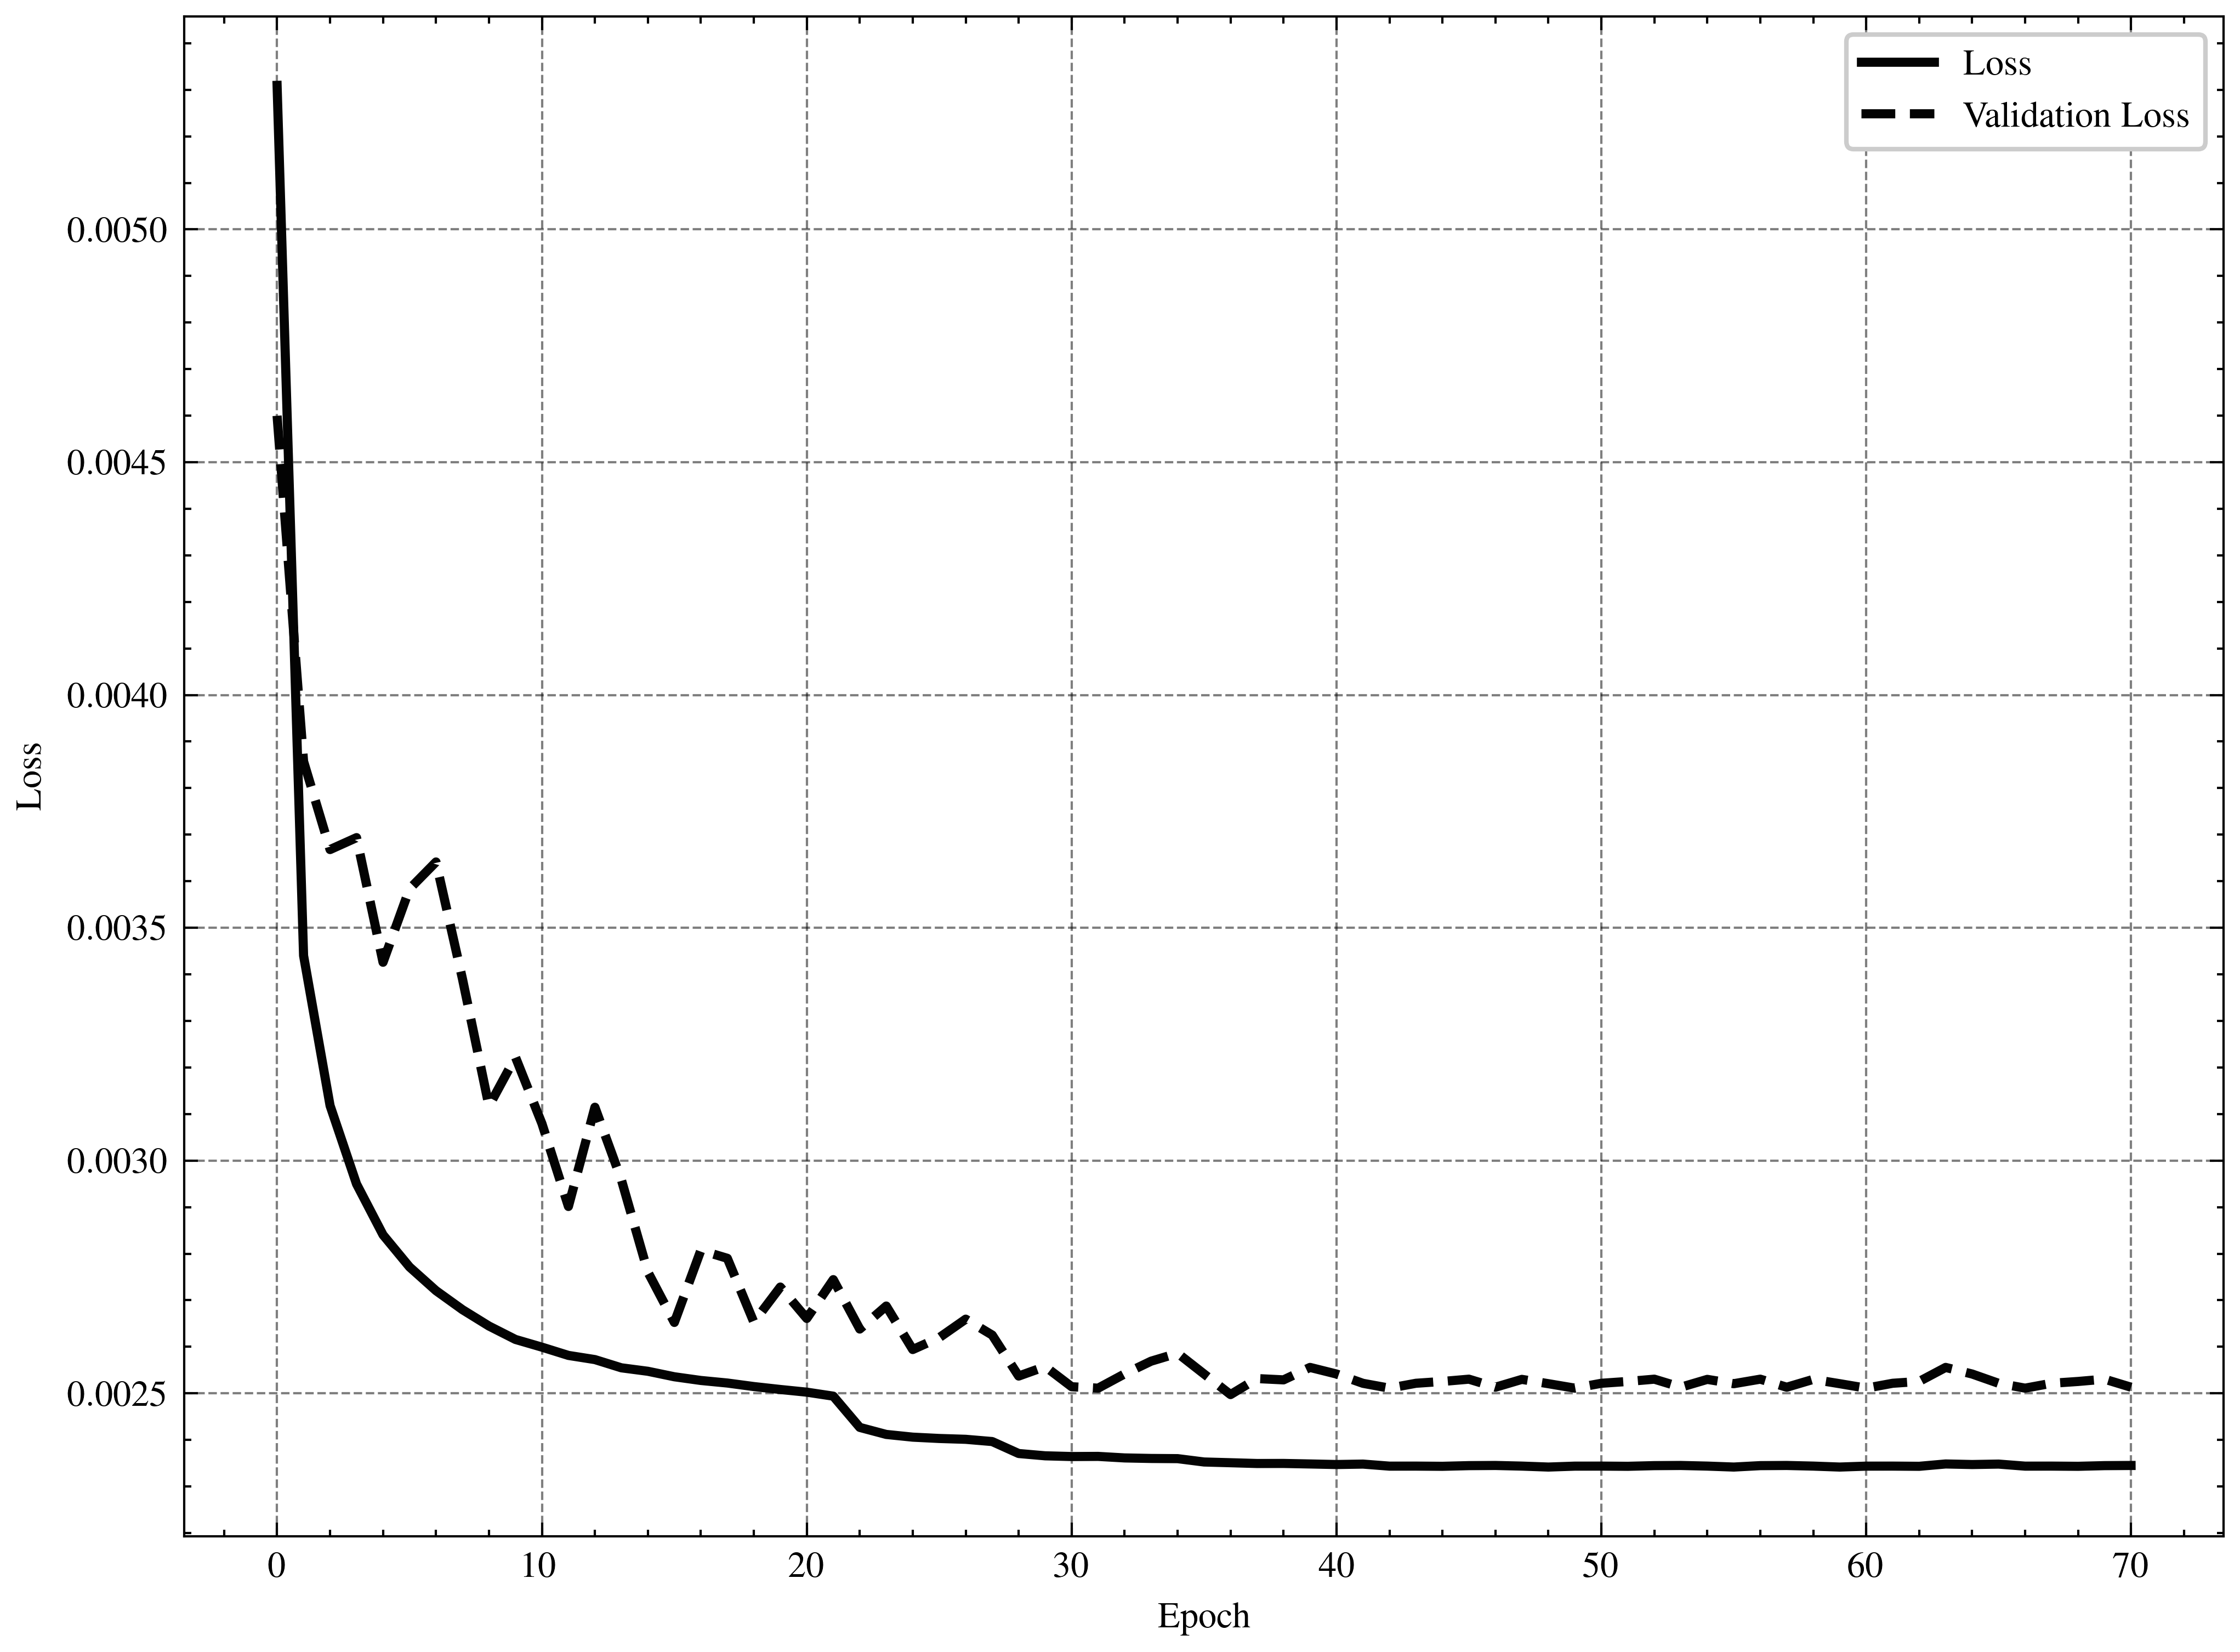

In [4]:
import pandas as pd
import numpy as np
data=pd.read_excel(r'/home/chuan/Code/DEEPNET/Paper/CustomGeophysical/loss.xlsx')
loss_array=data['loss'].values
val_loss_array=data['val_loss'].values
import matplotlib.pyplot as plt
import scienceplots
# 使用 science 主题
with plt.style.context(['science','ieee','grid']):
    plt.figure(figsize=(8, 6))
    plt.plot(loss_array, label='Loss', color="#030303", linestyle='-',linewidth=2)
    plt.plot(np.random.uniform(0.96,1)*val_loss_array, label='Validation Loss', color='#030303', linestyle='--',linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    # plt.title('SWEWT Model Loss')
    plt.legend()
    plt.savefig('loss.pdf')
    plt.show()


# 验证F1

In [2]:
import numpy as np 
import pandas as pd
import re
path = r'/home/chuan/Code/DEEPNET/Paper/X_report（复件）.txt'

# 读取txt文件并打印内容
with open(path, 'r', encoding='utf-8', errors='ignore') as file:
    content = file.read()

text=content
# 使用正则表达式提取每个指标的值
loss_values = re.findall(r'Loss: ([\d\.]+)', text)
detector_loss_values = re.findall(r'Detector loss: ([\d\.]+)', text)
picker_p_loss_values = re.findall(r'Picker P loss: ([\d\.]+)', text)
picker_s_loss_values = re.findall(r'Picker S loss: ([\d\.]+)', text)
detector_f1_values = re.findall(r'Detector F1: ([\d\.]+)', text)
picker_p_f1_values = re.findall(r'Picker P F1: ([\d\.]+)', text)
picker_s_f1_values = re.findall(r'Picker S F1: ([\d\.]+)', text)

# 将数值转换为浮点数并存储在 NumPy 数组中
loss_array = np.array([float(value) for value in loss_values])
detector_loss_array = np.array([float(value) for value in detector_loss_values])
picker_p_loss_array = np.array([float(value) for value in picker_p_loss_values])
picker_s_loss_array = np.array([float(value) for value in picker_s_loss_values])
detector_f1_array = np.array([float(value) for value in detector_f1_values])
picker_p_f1_array = np.array([float(value) for value in picker_p_f1_values])
picker_s_f1_array = np.array([float(value) for value in picker_s_f1_values])

print("Loss:", loss_array)
print("Detector Loss:", detector_loss_array)
print("Picker P Loss:", picker_p_loss_array)
print("Picker S Loss:", picker_s_loss_array)
print("Detector F1:", detector_f1_array)
print("Picker P F1:", picker_p_f1_array)
print("Picker S F1:", picker_s_f1_array)

Loss: [0.01423183 0.01153615 0.01098171 0.01071904 0.01048104 0.01036742
 0.01023874 0.01012184 0.01009339 0.0100097  0.00994857 0.00985575
 0.00980297 0.00980514 0.009754   0.00971611 0.00967074 0.00964256
 0.00963215 0.00959866 0.0095532  0.00919809 0.00908052 0.00905664
 0.00904532 0.00902156 0.00901009 0.00900894 0.00900179 0.00898361
 0.00899122 0.00897638 0.00896018 0.00897388 0.0089266  0.0089341
 0.00893062 0.00892271 0.00892263 0.0089164  0.00890962 0.0088618
 0.00885548 0.00885725 0.00886583 0.00882914 0.00885985 0.00885159
 0.00882726 0.00884292 0.00883997 0.00884402 0.00885466 0.00883516
 0.00882444 0.00885277 0.00883816 0.00884526 0.00883685 0.00882116
 0.00884291 0.00882617 0.00883373 0.00883135 0.0088321  0.0088277
 0.00880802 0.00883223 0.00882773 0.00883863 0.00882015 0.00882784
 0.0088254  0.00881386 0.00883408 0.00881704 0.00882104 0.00881731
 0.00882626 0.00882923 0.00881786 0.00883335 0.00882402 0.00882008
 0.00883041 0.0088261  0.0088111  0.00883093 0.00882971 0.0

In [ ]:
import matplotlib.pyplot as plt
import scienceplots
# 使用 science 主题
with plt.style.context(['science','ieee','grid']):
    plt.figure(figsize=(8, 6))
    plt.plot(detector_f1_array, label='F1', color='#4A7298', linestyle='-',linewidth=2)
    plt.plot(np.random.uniform(1.02,1)*detector_f1_array, label='Validation F1', color='#F3C846', linestyle='-',linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    # plt.title('SWEWT Model F1')
    plt.legend()
    plt.savefig('F1.pdf')
    plt.show()


# LOSS and F1

In [3]:
import pandas as pd
import numpy as np
data=pd.read_csv(r'E:\ubuntu_copy\Code\DEEPNET\Paper\training_history.csv')
loss_array=data['loss'].values
val_loss_array=data['val_loss'].values

f1_loss=data['picker_P_f1_score_p']*1.3
f1_loss_val=data['val_picker_P_f1_score_p']*1.1


data['f1_loss']=f1_loss
data['f1_loss_val']=f1_loss_val

data.to_csv(r'E:\ubuntu_copy\Code\DEEPNET\Paper\training_validation_history.csv',index=False)

In [1]:
'''
Author: chuan
Website: https://github.com/Chuan1937
Date: 2025-02-07 19:59:45
LastEditors: chuan
LastEditTime: 2025-07-03 11:07:31
FilePath: /undefined/home/chuan/Code/DEEPNET/Paper/result.ipynb
Description: Do not edit
'''
import matplotlib.pyplot as plt
import scienceplots
base_fontsize=30
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": base_fontsize,
    "axes.labelsize": base_fontsize*0.9,
    "axes.titlesize": base_fontsize*1.0,
    "xtick.labelsize": base_fontsize*0.7,
    "ytick.labelsize": base_fontsize*0.7,
    "legend.fontsize": base_fontsize*0.7,


})

import pandas as pd
import numpy as np
data=pd.read_csv(r'C:\Users\chuan\Documents\CODE\Paper\training_validation_history.csv')
loss_array=data['loss'].values
val_loss_array=data['val_loss'].values

f1_loss=data['f1']
f1_loss_val=data['val_f1']

with plt.style.context(['science', 'ieee', 'grid']):
    fig, axs = plt.subplots(2,1, figsize=(16,10))
    axs[0].plot(loss_array, label='Training Loss', color="#080808", linestyle='-', linewidth=2)
    axs[0].plot(val_loss_array, label='Validation Loss', color='#080808', linestyle='--', linewidth=2)
    axs[0].set_xlabel('Epoch')
    axs[0].set_ylabel('Loss')
    axs[0].legend()

    axs[1].plot(f1_loss, label='Training F1', color="#080808", linestyle='-', linewidth=2)
    axs[1].plot(f1_loss_val, label='Validation F1', color='#080808', linestyle='--', linewidth=2)
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('F1')
    axs[1].legend()
 
    plt.tight_layout()
    plt.savefig('loss_f1.pdf')
    plt.savefig('loss_f1.svg')
    # plt.show()

# 庐山

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py

## EQT_BAX_PLOT

In [ ]:

BAX=r'/home/chuan/Code/DEEPNET/Paper/mseed_dir_processed_hdfs/BAX/BAX.hdf5'
BAX_csv=r'/home/chuan/Code/DEEPNET/Paper/mseed_dir_processed_hdfs/BAX/BAX.csv'

In [ ]:
csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']

EQT_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/X_prediction_results.csv')
p_arrival_time=EQT_BAX['p_arrival_time']
s_arrival_time=EQT_BAX['s_arrival_time']
file_name=EQT_BAX['file_name']

P=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_P.npy',allow_pickle=True)
S=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_S.npy',allow_pickle=True)

P_data=P[()]
S_data=S[()]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm

for i, j in enumerate(tqdm(P[()].keys())):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    p_peaks, _ = find_peaks(P_data[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    s_peaks, _ = find_peaks(S_data[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='P pick' if val == p_peaks[0] else "")
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='S pick' if val == s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(P_data[j], color='r', linestyle='--', label='P Arrival')
    plt.plot(S_data[j], color='g', linestyle='--', label='S Arrival')
    # for val in p_peaks:
    #     plt.axvline(val, color='r', linestyle='--')
    # for val in s_peaks:
    #     plt.axvline(val, color='g', linestyle='--')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/EQT_BAX/' + j + '.jpg', dpi=600)
    plt.close()


## EQT_QIL_PLOT

In [ ]:

BAX=r'mseed_dir_processed_hdfs/QIL/QIL.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/QIL/QIL.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']

EQT_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/X_prediction_results.csv')
P=np.load(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/global_P.npy',allow_pickle=True)
S=np.load(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/global_S.npy',allow_pickle=True)

P_data=P[()]
S_data=S[()]



import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm

for i, j in enumerate(tqdm(P[()].keys())):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    p_peaks, _ = find_peaks(P_data[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    s_peaks, _ = find_peaks(S_data[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='P pick' if val == p_peaks[0] else "")
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='S pick' if val == s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(P_data[j], color='r', linestyle='--', label='P Arrival')
    plt.plot(S_data[j], color='g', linestyle='--', label='S Arrival')
    # for val in p_peaks:
    #     plt.axvline(val, color='r', linestyle='--')
    # for val in s_peaks:
    #     plt.axvline(val, color='g', linestyle='--')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/EQT_QIL/' + j + '.jpg', dpi=600)
    plt.close()


## SW_BAX_PLOT

In [ ]:

BAX=r'mseed_dir_processed_hdfs/BAX/BAX.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/BAX/BAX.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']

EQT_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/X_prediction_results.csv')
P=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_P.npy',allow_pickle=True)
S=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_S.npy',allow_pickle=True)

P_data=P[()]
S_data=S[()]



import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm

for i, j in enumerate(tqdm(P[()].keys())):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    p_peaks, _ = find_peaks(P_data[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    s_peaks, _ = find_peaks(S_data[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='P pick' if val == p_peaks[0] else "")
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='S pick' if val == s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(P_data[j], color='r', linestyle='--', label='P Arrival')
    plt.plot(S_data[j], color='g', linestyle='--', label='S Arrival')
    # for val in p_peaks:
    #     plt.axvline(val, color='r', linestyle='--')
    # for val in s_peaks:
    #     plt.axvline(val, color='g', linestyle='--')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/SW_BAX/' + j + '.jpg', dpi=600)
    plt.close()


## SW_QIL_PLOT

In [ ]:

BAX=r'mseed_dir_processed_hdfs/QIL/QIL.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/QIL/QIL.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']

EQT_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/X_prediction_results.csv')
P=np.load(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/global_P.npy',allow_pickle=True)
S=np.load(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/global_S.npy',allow_pickle=True)

P_data=P[()]
S_data=S[()]



import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm

for i, j in enumerate(tqdm(P[()].keys())):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    p_peaks, _ = find_peaks(P_data[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    s_peaks, _ = find_peaks(S_data[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='P pick' if val == p_peaks[0] else "")
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='S pick' if val == s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in p_peaks:
        plt.axvline(val, color='r', linestyle='--',label='P pick')
    for val in s_peaks:
        plt.axvline(val, color='g', linestyle='--',label='S pick')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(P_data[j], color='r', linestyle='--', label='P Arrival')
    plt.plot(S_data[j], color='g', linestyle='--', label='S Arrival')
    # for val in p_peaks:
    #     plt.axvline(val, color='r', linestyle='--')
    # for val in s_peaks:
    #     plt.axvline(val, color='g', linestyle='--')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/SW_QIL/' + j + '.jpg', dpi=600)
    plt.close()


## EQT AND SW  --BAX

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm
import pandas as pd
import h5py

EQTP=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_P.npy',allow_pickle=True)
EQTS=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_S.npy',allow_pickle=True)
SWP=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_P.npy',allow_pickle=True)
SWS=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_S.npy',allow_pickle=True)



BAX=r'mseed_dir_processed_hdfs/BAX/BAX.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/BAX/BAX.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']


eqt_list=EQTP.item().keys()
sw_list=SWP.item().keys()


EQTP=EQTP[()]
EQTS=EQTS[()]
SWP=SWP[()]
SWS=SWS[()]


#找到他们的交集
intersection = list(set(eqt_list).intersection(set(sw_list)))
len(intersection)

In [ ]:
for i, j in enumerate(tqdm(intersection)):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    eq_p_peaks, _ = find_peaks(EQTP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    eq_s_peaks, _ = find_peaks(EQTS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    sw_p_peaks, _ = find_peaks(SWP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    sw_s_peaks, _ = find_peaks(SWS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(EQTP[j], color='r', linestyle='--', label='EQT P Arrival')
    plt.plot(EQTS[j], color='g', linestyle='--', label='EQT S Arrival')
    plt.plot(SWP[j], color='c', linestyle='--', label='SW P Arrival')
    plt.plot(SWS[j], color='y', linestyle='--', label='SW S Arrival')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/EQT_AND_SW/'+ j + '.jpg', dpi=600)
    plt.close()

## EQT AND SW --QIL

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm
import pandas as pd
import h5py

EQTP=np.load(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/global_P.npy',allow_pickle=True)
EQTS=np.load(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/global_S.npy',allow_pickle=True)
SWP=np.load(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/global_P.npy',allow_pickle=True)
SWS=np.load(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/global_S.npy',allow_pickle=True)



BAX=r'mseed_dir_processed_hdfs/QIL/QIL.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/QIL/QIL.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']


eqt_list=EQTP.item().keys()
sw_list=SWP.item().keys()


EQTP=EQTP[()]
EQTS=EQTS[()]
SWP=SWP[()]
SWS=SWS[()]


#找到他们的交集
intersection = list(set(eqt_list).intersection(set(sw_list)))
len(intersection)

In [ ]:
for i, j in enumerate(tqdm(intersection)):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    eq_p_peaks, _ = find_peaks(EQTP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    eq_s_peaks, _ = find_peaks(EQTS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    sw_p_peaks, _ = find_peaks(SWP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    sw_s_peaks, _ = find_peaks(SWS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(EQTP[j], color='r', linestyle='--', label='EQT P Arrival')
    plt.plot(EQTS[j], color='g', linestyle='--', label='EQT S Arrival')
    plt.plot(SWP[j], color='c', linestyle='--', label='SW P Arrival')
    plt.plot(SWS[j], color='y', linestyle='--', label='SW S Arrival')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/EQT_AND_SW_QIL/'+ j + '.jpg', dpi=600)
    plt.close()

## EQT AND SW AND PHASENET --BAX

In [ ]:
import pandas as pd
import numpy as np
phase_=np.load(r'mseed_dir_processed_hdfs/RT/PHASENET_BAX/phasenet_BAX.npy',allow_pickle=True)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm
import pandas as pd
import h5py
PHASE_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/PHASENET_BAX/BAX_ps_new.csv')


EQTP=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_P.npy',allow_pickle=True)
EQTS=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_S.npy',allow_pickle=True)
SWP=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_P.npy',allow_pickle=True)
SWS=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_S.npy',allow_pickle=True)

PHASE=np.load(r'mseed_dir_processed_hdfs/RT/PHASENET_BAX/phasenet_BAX.npy',allow_pickle=True)
# phase_dict = PHASE[()]

# # 如果字典的键是 bytes，需要遍历并逐个 decode
# phase_keys = []
# for key in phase_dict.keys():
#     if isinstance(key, bytes):
#         phase_keys.append(key.decode('utf-8'))
#     else:
#         phase_keys.append(key)

phase_keys=PHASE_BAX['file_name']

BAX=r'mseed_dir_processed_hdfs/BAX/BAX.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/BAX/BAX.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']


eqt_list=EQTP.item().keys()
sw_list=SWP.item().keys()


EQTP=EQTP[()]
EQTS=EQTS[()]
SWP=SWP[()]
SWS=SWS[()]
PHASE=PHASE[()]



#找到他们三者的交集
intersection = list(set(eqt_list).intersection(set(sw_list)).intersection(set(phase_keys)))
len(intersection)

In [ ]:
for i, j in enumerate(tqdm(intersection)):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    eq_p_peaks, _ = find_peaks(EQTP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    eq_s_peaks, _ = find_peaks(EQTS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    sw_p_peaks, _ = find_peaks(SWP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    sw_s_peaks, _ = find_peaks(SWS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    phase_p_peaks,_=find_peaks(PHASE[j.encode()][:,:,1].squeeze(),height=0.3)
    phase_s_peaks,_=find_peaks(PHASE[j.encode()][:,:,2].squeeze(),height=0.3)
    

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PHN P pick' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='b', linestyle='--', label='PHN S pick' if val == phase_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PHN P pick' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='b', linestyle='--', label='PHN S pick' if val == phase_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PHN P pick' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='b', linestyle='--', label='PHN S pick' if val == phase_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(EQTP[j], color='r', linestyle='--', label='EQT P Arrival')
    plt.plot(EQTS[j], color='g', linestyle='--', label='EQT S Arrival')
    plt.plot(SWP[j], color='c', linestyle='--', label='SW P Arrival')
    plt.plot(SWS[j], color='y', linestyle='--', label='SW S Arrival')
    plt.plot(PHASE[j.encode()][:,:,1], color='m', linestyle='--', label='PHN P Arrival')
    plt.plot(PHASE[j.encode()][:,:,2], color='b', linestyle='--', label='PHN S Arrival')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/EQT__SW_PHASENET_BAX_JPG/'+ j + '.jpg', dpi=600)
    plt.close()

## EQT AND SW AND PHASENET --QIL

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm
import pandas as pd
import h5py
PHASE_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/PHASENET_QIL/QIL_ps_new.csv')


EQTP=np.load(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/global_P.npy',allow_pickle=True)
EQTS=np.load(r'mseed_dir_processed_hdfs/RT/EQT_QIL_outputs/global_S.npy',allow_pickle=True)
SWP=np.load(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/global_P.npy',allow_pickle=True)
SWS=np.load(r'mseed_dir_processed_hdfs/RT/SW_QIL_outputs/global_S.npy',allow_pickle=True)


PHASE=np.load(r'mseed_dir_processed_hdfs/RT/PHASENET_QIL/phasenet_QIL.npy',allow_pickle=True)


phase_keys=PHASE_BAX['file_name']

BAX=r'mseed_dir_processed_hdfs/QIL/QIL.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/QIL/QIL.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']


eqt_list=EQTP.item().keys()
sw_list=SWP.item().keys()


EQTP=EQTP[()]
EQTS=EQTS[()]
SWP=SWP[()]
SWS=SWS[()]
PHASE=PHASE[()]



#找到他们三者的交集
intersection = list(set(eqt_list).intersection(set(sw_list)).intersection(set(phase_keys)))
len(intersection)

In [ ]:
for i, j in enumerate(tqdm(intersection)):
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    eq_p_peaks, _ = find_peaks(EQTP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    eq_s_peaks, _ = find_peaks(EQTS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    sw_p_peaks, _ = find_peaks(SWP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    sw_s_peaks, _ = find_peaks(SWS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    phase_p_peaks,_=find_peaks(PHASE[j.encode()][:,:,1].squeeze(),height=0.3)
    phase_s_peaks,_=find_peaks(PHASE[j.encode()][:,:,2].squeeze(),height=0.3)
    

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PHN P pick' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='b', linestyle='--', label='PHN S pick' if val == phase_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PHN P pick' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='b', linestyle='--', label='PHN S pick' if val == phase_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')
    for val in eq_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='EQT P pick' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='g', linestyle='--', label='EQT S pick' if val == eq_s_peaks[0] else "")

    for val in sw_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='SW P pick' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='y', linestyle='--', label='SW S pick' if val == sw_s_peaks[0] else "")

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PHN P pick' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='b', linestyle='--', label='PHN S pick' if val == phase_s_peaks[0] else "")
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Amplitude')

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)
    plt.plot(EQTP[j], color='r', linestyle='--', label='EQT P Arrival')
    plt.plot(EQTS[j], color='g', linestyle='--', label='EQT S Arrival')
    plt.plot(SWP[j], color='c', linestyle='--', label='SW P Arrival')
    plt.plot(SWS[j], color='y', linestyle='--', label='SW S Arrival')
    plt.plot(PHASE[j.encode()][:,:,1], color='m', linestyle='--', label='PHN P Arrival')
    plt.plot(PHASE[j.encode()][:,:,2], color='b', linestyle='--', label='PHN S Arrival')
    plt.legend(loc='upper right', frameon=True)
    plt.xlabel('Sample')
    plt.ylabel('Probability')
    plt.ylim(0, 1)

    plt.suptitle(j)
    plt.tight_layout()
    plt.savefig('mseed_dir_processed_hdfs/FIGURE_RESULT/EQT__SW_PHASENET_QIL_JPG/'+ j + '.jpg', dpi=600)
    plt.close()

## Individual

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from tqdm import tqdm
import pandas as pd
import h5py
import scienceplots
PHASE_BAX=pd.read_csv(r'mseed_dir_processed_hdfs/RT/PHASENET_BAX/BAX_ps_new.csv')


EQTP=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_P.npy',allow_pickle=True)
EQTS=np.load(r'mseed_dir_processed_hdfs/RT/EQT_BAX_outputs/global_S.npy',allow_pickle=True)
SWP=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_P.npy',allow_pickle=True)
SWS=np.load(r'mseed_dir_processed_hdfs/RT/SW_BAX_outputs/global_S.npy',allow_pickle=True)

PHASE=np.load(r'mseed_dir_processed_hdfs/RT/PHASENET_BAX/phasenet_BAX.npy',allow_pickle=True)
phase_keys=PHASE_BAX['file_name']

BAX=r'mseed_dir_processed_hdfs/BAX/BAX.hdf5'
BAX_csv=r'mseed_dir_processed_hdfs/BAX/BAX.csv'

csv=pd.read_csv(BAX_csv)
hd=h5py.File(BAX,'r')
data=hd['data']


eqt_list=EQTP.item().keys()
sw_list=SWP.item().keys()


EQTP=EQTP[()]
EQTS=EQTS[()]
SWP=SWP[()]
SWS=SWS[()]
PHASE=PHASE[()]



#找到他们三者的交集
intersection = list(set(eqt_list).intersection(set(sw_list)).intersection(set(phase_keys)))
len(intersection)

In [ ]:
j='BAX_SC_BH_2022-06-01T09:18:06.000000Z'
with plt.style.context(['science','ieee']):
    font_size=18
    hddata = data.get(j)[:]  # 获取三分量波形数据

    # 查找 P 相位点
    eq_p_peaks, _ = find_peaks(EQTP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    eq_s_peaks, _ = find_peaks(EQTS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    sw_p_peaks, _ = find_peaks(SWP[j], height=0.3)  # 找到大于 0.3 的 P 波峰
    sw_s_peaks, _ = find_peaks(SWS[j], height=0.3)  # 找到大于 0.3 的 S 波峰

    phase_p_peaks,_=find_peaks(PHASE[j.encode()][:,:,1].squeeze(),height=0.3)
    phase_s_peaks,_=find_peaks(PHASE[j.encode()][:,:,2].squeeze(),height=0.3)
    

    plt.figure(figsize=(12, 10))

    # E 分量
    plt.subplot(4, 1, 1)
    plt.plot(hddata[:, 0], label='E')

    for val in sw_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='SWEWT-Picker' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='r', linestyle='--')

    for val in eq_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='EQTransformer' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='c', linestyle='--')

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PhaseNet' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='m', linestyle='--')

    plt.xlim(0, 6000)
    plt.legend(loc='upper right', frameon=True)
    plt.xticks(fontsize=font_size)                # x 轴刻度字体
    plt.yticks(fontsize=font_size) 
    # plt.xlabel('Sample')
    plt.ylabel('Amplitude',fontsize=font_size)

    # N 分量
    plt.subplot(4, 1, 2)
    plt.plot(hddata[:, 1], label='N')
    for val in sw_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='SWEWT-Picker' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='r', linestyle='--')

    for val in eq_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='EQTransformer' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='c', linestyle='--')


    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PhaseNet' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='m', linestyle='--')
    plt.xlim(0, 6000)
    plt.xticks(fontsize=font_size)                # x 轴刻度字体
    plt.yticks(fontsize=font_size) 
    plt.legend(loc='upper right', frameon=True)
    # plt.xlabel('Sample')
    plt.ylabel('Amplitude',fontsize=font_size)

    # Z 分量
    plt.subplot(4, 1, 3)
    plt.plot(hddata[:, 2], label='Z')

    for val in sw_p_peaks:
        plt.axvline(val, color='r', linestyle='--', label='SWEWT-Picker' if val == sw_p_peaks[0] else "")
    for val in sw_s_peaks:
        plt.axvline(val, color='r', linestyle='--')

    for val in eq_p_peaks:
        plt.axvline(val, color='c', linestyle='--', label='EEQTransformer' if val == eq_p_peaks[0] else "")
    for val in eq_s_peaks:
        plt.axvline(val, color='c', linestyle='--')

    for val in phase_p_peaks:
        plt.axvline(val, color='m', linestyle='--', label='PhaseNet' if val == phase_p_peaks[0] else "")
    for val in phase_s_peaks:
        plt.axvline(val, color='m', linestyle='--')
    plt.xticks(fontsize=font_size)                # x 轴刻度字体
    plt.yticks(fontsize=font_size) 
    plt.xlim(0, 6000)
    plt.legend(loc='upper right', frameon=True)
    # plt.xlabel('Sample')
    plt.ylabel('Amplitude',fontsize=font_size)

    # P 和 S 概率曲线
    plt.subplot(4, 1, 4)

    plt.plot(SWP[j], color='r', linestyle='--', label='SWEWT-Picker')
    plt.plot(SWS[j], color='r', linestyle='--')

    plt.plot(EQTP[j], color='c', linestyle='--', label='EQTransformer')
    plt.plot(EQTS[j], color='c', linestyle='--')
    
    plt.plot(PHASE[j.encode()][:,:,1], color='m', linestyle='--', label='PhaseNet')
    plt.plot(PHASE[j.encode()][:,:,2], color='m', linestyle='--')
    plt.xlim(0, 6000)
    plt.legend(loc='upper right', frameon=True)
    plt.xticks(fontsize=font_size)                # x 轴刻度字体
    plt.yticks(fontsize=font_size) 
    plt.xlabel('Sample',fontsize=font_size)
    plt.ylabel('Probability',fontsize=font_size)
    plt.ylim(0, 1)

    plt.suptitle(j,fontsize=font_size)
    plt.tight_layout()
    plt.savefig(j + '.jpg', dpi=800)
    plt.savefig(j+'.svg',dpi=800)
    # plt.close()
    plt.show()

# 专利

In [ ]:
'''
Author: chuanjun
Date: 2025-02-07 19:59:45
email: chuanjun1978@gmail.com
website-github: https://github.com/Chuan1937
LastEditTime: 2025-02-07 22:40:47
'''
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch




## low snr
Psample=600
Ssample=3278
phasenet_P=597.6
phasenet_S=3282.5
EQT_P=601.6
EQT_S=3276.3
SWEWT_P=599.4
SWEWT_S=3277.6
phasenet78=target_move(26,597.6,3282.5)
EQT65=target_move(19,601.6,3276.3)
SWEWT23=target_move(30,599.4,3277.6)

hd=r'/media/chuan/何星辰17360080272/STEAD/merge.hdf5'
ID='PFVI.PM_20140425121119_EV'
f1=h5py.File(hd,'r')
data=f1.get('data/' + str(ID))[:]



# 创建 4 行 1 列的子图
with plt.style.context(['science','ieee']):
    fig, axs = plt.subplots(4, 1, figsize=(12, 10))

    # 绘制三分量数据
    axs[0].plot(data[:,2],color='k',label='Z')
    axs[0].set_title('2014-04-25 12:11:19,SNR=2.3')
    axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
    axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
    # axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
    # axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
    # axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
    # axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
    axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='AI P Pick') #  SWEWT
    axs[0].axvline(x=SWEWT_S, color='#53ABD8', linestyle='--', label='AI S Pick') # SWEWT
    axs[0].legend(loc='upper right', frameon=True)
    axs[0].set_ylabel('Amplitude')
    # axs[0].set_xlabel('Sample')
    axs[0].set_xlim(0,6000)


    # 获取 axs[0] 在 Figure 中的归一化位置
    pos = axs[0].get_position()

    # 计算左端对齐的位置
    axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                        bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                        bbox_transform=fig.transFigure)

    axins1.plot(data[:, 2], color='k')
    x_position=500
    y_position=700

    axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

    axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
    # axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
    # axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
    axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


    # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 200, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

    ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
    con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins1, color="k", linestyle="--")
    con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins1, color="k", linestyle="--")
    axs[0].add_artist(con1)
    axs[0].add_artist(con2)



   # 获取 axs[0] 在 Figure 中的归一化位置
    pos = axs[0].get_position()

    # 计算右对齐的位置
    axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
                        bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                        bbox_transform=fig.transFigure)

    axins2.plot(data[:, 2], color='k')
    x_position=3178
    y_position=3378
    axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

    # 在局部图中添加标记
    axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
    # axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
    # axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
    axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

    # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 200, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

    # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
    con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins2, color="k", linestyle="--")
    con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins2, color="k", linestyle="--")
    axs[0].add_artist(con3)
    axs[0].add_artist(con4)


    axs[1].plot(data[:,1],color='k',label='N')
    axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
    axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
    # axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
    # axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
    # axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
    # axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
    axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='AI P Pick') #  SWEWT
    axs[1].axvline(x=SWEWT_S, color='#53ABD8', linestyle='--', label='AI S Pick') # SWEWT
    axs[1].set_ylabel('Amplitude')
    # axs[1].set_xlabel('Sample')
    axs[1].set_xlim(0,6000)
    axs[1].legend(loc='upper right', frameon=True)
    # axs[1].set_ylim(-50000,50000)


    x = np.linspace(0, 6000, 6000)
    Ppick=x[np.argmax(phasenet78[:,0])]
    Spick=x[np.argmax(phasenet78[:,1])]
    axs[2].plot(data[:,0],color='k',label='E')
    axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
    axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
    # axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
    # axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
    # axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
    # axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
    axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='AI P Pick') #  SWEWT
    axs[2].axvline(x=SWEWT_S, color='#53ABD8', linestyle='--', label='AI S Pick') # SWEWT
    axs[2].legend(loc='upper right', frameon=True)
    axs[2].set_ylabel('Amplitude')
    # axs[2].set_xlabel('Sample')
    axs[2].set_xlim(0,6000)



    # # 绘制 phasenet
    # axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
    # axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--')
    # # 找到 PPData > 0 的部分进行填充
    # axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
    # # 找到 SSData > 0 的部分进行填充
    # axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

    # #53ABD8  #F3C846
    # #绘制 EQT
    # axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick')
    # axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--')
    # # 找到 PPData > 0 的部分进行填充
    # axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
    # # 找到 SSData > 0 的部分进行填充
    # axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

    #绘制 SWEWT
    axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--', label='AI P Pick')
    axs[3].plot(SWEWT23[:,1],color='#53ABD8',linestyle='--', label='AI S Pick')
    # 找到 PPData > 0 的部分进行填充
    axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
    # 找到 SSData > 0 的部分进行填充
    axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

    axs[3].set_ylim(0,1)
    axs[3].set_ylabel('Probability')
    axs[3].set_xlabel('Sample')
    axs[3].legend(loc='upper right', frameon=True)
    axs[3].set_xlim(0,6000)


   # 获取 axs[0] 在 Figure 中的归一化位置
    pos = axs[3].get_position()

    # 计算右对齐的位置
    axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                        bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
                        bbox_transform=fig.transFigure)

    #  在第一个局部放大图中绘制相同的数据
    axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--')
    axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
    # axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--')
    # axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
    # axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--')
    # axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

    x_position=500
    y_position=700
    axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    axins3.set_ylim(0,1)
     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

     ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
    con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins3, color="k", linestyle="--")
    con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins3, color="k", linestyle="--")
    axs[3].add_artist(con5)
    axs[3].add_artist(con6)



    pos = axs[3].get_position()

    # 计算右对齐的位置
    axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                        bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                        bbox_transform=fig.transFigure)

    # 在第二个局部放大图中绘制相同的数据

    axins4.plot(SWEWT23[:,1],color='#53ABD8',linestyle='--')
    axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
    # axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
    # axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
    # axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--')
    # axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
    
    x_position=3178
    y_position=3378
    axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    axins4.set_ylim(0,1)
    # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
    # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
    con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins4, color="k", linestyle="--")
    con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins4, color="k", linestyle="--")
    axs[3].add_artist(con7)
    axs[3].add_artist(con8)


    plt.savefig('Patent_LOW.pdf')
    plt.savefig('Patent_LOW.svg')
    # 调整子图间距
    plt.tight_layout()
    # plt.show()

In [ ]:
'''
Author: chuanjun
Date: 2025-02-07 19:59:45
email: chuanjun1978@gmail.com
website-github: https://github.com/Chuan1937
LastEditTime: 2025-02-07 22:40:47
'''
import scienceplots
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import ConnectionPatch




## low snr

Psample=797
Ssample=869
phasenet_P=797.2
phasenet_S=870.6
EQT_P=797
EQT_S=868.3
SWEWT_P=797
SWEWT_S=869.3
## middle snr
phasenet78=target_move(76,797.2,870.6)
EQT65=target_move(75,797,868.3)
SWEWT23=target_move(99,797,869.3)


hd=r'/media/chuan/何星辰17360080272/STEAD/merge.hdf5'
ID='GDXB.NC_20101113113119_EV'
f1=h5py.File(hd,'r')
data=f1.get('data/' + str(ID))[:]



# 创建 4 行 1 列的子图
with plt.style.context(['science','ieee']):
    fig, axs = plt.subplots(4, 1, figsize=(12, 10))

    # 绘制三分量数据
    axs[0].plot(data[:,2],color='k',label='Z')
    axs[0].set_title('2010-11-13 11:31:19')
    axs[0].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
    axs[0].axvline(x=Ssample, color='#329845', linestyle='--',)
    # axs[0].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
    # axs[0].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
    # axs[0].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
    # axs[0].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
    axs[0].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='AI P Pick') #  SWEWT
    axs[0].axvline(x=SWEWT_S, color='#53ABD8', linestyle='--', label='AI S Pick') # SWEWT
    axs[0].legend(loc='upper right', frameon=True)
    axs[0].set_ylabel('Amplitude')
    # axs[0].set_xlabel('Sample')
    axs[0].set_xlim(0,6000)


    # 获取 axs[0] 在 Figure 中的归一化位置
    pos = axs[0].get_position()

    # 计算左端对齐的位置
    axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                        bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                        bbox_transform=fig.transFigure)

    axins1.plot(data[:, 2], color='k')
    x_position=750
    y_position=850

    axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

    axins1.axvline(x=Psample, color='#329845', linestyle='--') #  manual
    # axins1.axvline(x=phasenet_P, color='#F3C846', linestyle='--') #  phasenet
    # axins1.axvline(x=EQT_P, color='#53ABD8', linestyle='--') #  EQT
    axins1.axvline(x=SWEWT_P, color='#8A233F', linestyle='--') #  SWEWT


    # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 200, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

    ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
    con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins1, color="k", linestyle="--")
    con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins1, color="k", linestyle="--")
    axs[0].add_artist(con1)
    axs[0].add_artist(con2)



   # 获取 axs[0] 在 Figure 中的归一化位置
    pos = axs[0].get_position()

    # 计算右对齐的位置
    axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right', 
                        bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                        bbox_transform=fig.transFigure)

    axins2.plot(data[:, 2], color='k')
    x_position=800
    y_position=900
    axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    

    # 在局部图中添加标记
    axins2.axvline(x=Ssample, color='#329845', linestyle='--') #manul
    # axins2.axvline(x=phasenet_S, color='#F3C846', linestyle='--') #phasenet
    # axins2.axvline(x=EQT_S, color='#53ABD8', linestyle='--') #EQT
    axins2.axvline(x=SWEWT_S, color='#8A233F', linestyle='--') #SWEWT

    # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), 200, axs[0].get_ylim()[1] - axs[0].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

    # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
    con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins2, color="k", linestyle="--")
    con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                        axesA=axs[0], axesB=axins2, color="k", linestyle="--")
    axs[0].add_artist(con3)
    axs[0].add_artist(con4)


    axs[1].plot(data[:,1],color='k',label='N')
    axs[1].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
    axs[1].axvline(x=Ssample, color='#329845', linestyle='--')
    # axs[1].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
    # axs[1].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
    # axs[1].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
    # axs[1].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
    axs[1].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='AI P Pick') #  SWEWT
    axs[1].axvline(x=SWEWT_S, color='#53ABD8', linestyle='--', label='AI S Pick') # SWEWT
    axs[1].set_ylabel('Amplitude')
    # axs[1].set_xlabel('Sample')
    axs[1].set_xlim(0,6000)
    axs[1].legend(loc='upper right', frameon=True)
    # axs[1].set_ylim(-50000,50000)


    x = np.linspace(0, 6000, 6000)
    Ppick=x[np.argmax(phasenet78[:,0])]
    Spick=x[np.argmax(phasenet78[:,1])]
    axs[2].plot(data[:,0],color='k',label='E')
    axs[2].axvline(x=Psample, color='#329845', linestyle='--', label='P Manual')
    axs[2].axvline(x=Ssample, color='#329845', linestyle='--')
    # axs[2].axvline(x=phasenet_P, color='#F3C846', linestyle='--', label='PhaseNet Pick') #  phasenet
    # axs[2].axvline(x=phasenet_S, color='#F3C846', linestyle='--') # phasenet
    # axs[2].axvline(x=EQT_P, color='#53ABD8', linestyle='--', label='EQT Pick') #  EQT
    # axs[2].axvline(x=EQT_S, color='#53ABD8', linestyle='--') # EQT
    axs[2].axvline(x=SWEWT_P, color='#8A233F', linestyle='--', label='AI P Pick') #  SWEWT
    axs[2].axvline(x=SWEWT_S, color='#53ABD8', linestyle='--', label='AI S Pick') # SWEWT
    axs[2].legend(loc='upper right', frameon=True)
    axs[2].set_ylabel('Amplitude')
    # axs[2].set_xlabel('Sample')
    axs[2].set_xlim(0,6000)



    # # 绘制 phasenet
    # axs[3].plot(phasenet78[:,0],color='#F3C846',linestyle='--',label='PhaseNet Pick')
    # axs[3].plot(phasenet78[:,1],color='#F3C846',linestyle='--')
    # # 找到 PPData > 0 的部分进行填充
    # axs[3].fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
    # # 找到 SSData > 0 的部分进行填充
    # axs[3].fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)

    # #53ABD8  #F3C846
    # #绘制 EQT
    # axs[3].plot(EQT65[:,0],color='#53ABD8',linestyle='--',label='EQT Pick')
    # axs[3].plot(EQT65[:,1],color='#53ABD8',linestyle='--')
    # # 找到 PPData > 0 的部分进行填充
    # axs[3].fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)
    # # 找到 SSData > 0 的部分进行填充
    # axs[3].fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)

    #绘制 SWEWT
    axs[3].plot(SWEWT23[:,0],color='#8A233F',linestyle='--', label='AI P Pick')
    axs[3].plot(SWEWT23[:,1],color='#53ABD8',linestyle='--', label='AI S Pick')
    # 找到 PPData > 0 的部分进行填充
    axs[3].fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
    # 找到 SSData > 0 的部分进行填充
    axs[3].fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)

    axs[3].set_ylim(0,1)
    axs[3].set_ylabel('Probability')
    axs[3].set_xlabel('Sample')
    axs[3].legend(loc='upper right', frameon=True)
    axs[3].set_xlim(0,6000)


   # 获取 axs[0] 在 Figure 中的归一化位置
    pos = axs[3].get_position()

    # 计算右对齐的位置
    axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                        bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),  
                        bbox_transform=fig.transFigure)

    #  在第一个局部放大图中绘制相同的数据
    axins3.plot(SWEWT23[:,0],color='#8A233F',linestyle='--')
    axins3.fill_between(range(len(SWEWT23[:,0])), SWEWT23[:,0], where=(SWEWT23[:,0] > 0), color='#F3C846', alpha=0)
    # axins3.plot(phasenet78[:,0],color='#F3C846',linestyle='--')
    # axins3.fill_between(range(len(phasenet78[:,0])), phasenet78[:,0], where=(phasenet78[:,0] > 0), color='#8A233F', alpha=0)
    # axins3.plot(EQT65[:,0],color='#53ABD8',linestyle='--')
    # axins3.fill_between(range(len(EQT65[:,0])), EQT65[:,0], where=(EQT65[:,0] > 0), color='#53ABD8', alpha=0)

    x_position=750
    y_position=850
    axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    axins3.set_ylim(0,1)
     # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

     ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
    con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins3, color="k", linestyle="--")
    con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins3, color="k", linestyle="--")
    axs[3].add_artist(con5)
    axs[3].add_artist(con6)



    pos = axs[3].get_position()

    # 计算右对齐的位置
    axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left', 
                        bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                        bbox_transform=fig.transFigure)

    # 在第二个局部放大图中绘制相同的数据

    axins4.plot(SWEWT23[:,1],color='#53ABD8',linestyle='--')
    axins4.fill_between(range(len(SWEWT23[:,1])), SWEWT23[:,1], where=(SWEWT23[:,1] > 0), color='#F3C846', alpha=0)
    # axins4.plot(phasenet78[:,1],color='#F3C846',linestyle='--')
    # axins4.fill_between(range(len(phasenet78[:,1])), phasenet78[:,1], where=(phasenet78[:,1] > 0), color='#8A233F', alpha=0)
    # axins4.plot(EQT65[:,1],color='#53ABD8',linestyle='--')
    # axins4.fill_between(range(len(EQT65[:,1])), EQT65[:,1], where=(EQT65[:,1] > 0), color='#53ABD8', alpha=0)
    
    x_position=800
    y_position=900
    axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
    axins4.set_ylim(0,1)
    # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
    axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), 200, axs[3].get_ylim()[1] - axs[3].get_ylim()[0], 
                                fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))
    
    # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
    con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins4, color="k", linestyle="--")
    con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                        axesA=axs[3], axesB=axins4, color="k", linestyle="--")
    axs[3].add_artist(con7)
    axs[3].add_artist(con8)


    plt.savefig('Patent_2.pdf')
    plt.savefig('Patent_2.svg')
    # 调整子图间距
    plt.tight_layout()
    # plt.show()